# DeFi Pulse: data, EDA, preprocessing, training, and evaluation

A runnable walkthrough of the **implemented baseline pipeline** for the frozen
200-pool Ethereum Uniswap v3 TOKEN/WETH cohort. It reads cached public data,
constructs 30% deterioration and percentage-change targets, performs exploratory
analysis, trains five fixed baselines at 1h/6h/24h, evaluates them, and exports
charts, predictions, and model bundles. **No Graph queries or API key are needed.**

**Interpretation:** all USD targets are provisional; this cohort's outcomes have
already been explored. The chronological test is a development diagnostic, not
an untouched final test. Poor results and missing evidence remain visible.

Contents:
1. Setup and fixed experiment
2. Source records, provenance, and quality checks
3. Versioned targets and chronological splits
4. First-day and three-day EDA
5. Training-only statistical comparisons
6. Preprocessing and baseline training
7. Classification and regression evaluation charts
8. Coefficients, pool-level predictions, exports, and conclusions

Open in VS Code using the project `.venv` Python kernel, or launch JupyterLab.
Choose **Restart Kernel and Run All** to reproduce everything. Cached data under
`data/diagnostic_200/` is required and is ignored by Git. The executed notebook
retains outputs for reading without rerunning. Setup commands are in `notebooks/README.md`.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, inspect, importlib.metadata
from datetime import datetime, timezone

# Work whether Jupyter starts in the repository root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/defi_pulse/baselines.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the defi-pulse repository or notebooks directory.")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
SOURCE = ROOT / "data/diagnostic_200"
OUTPUT = ROOT / "data/notebook_outputs/defi_pulse_baseline"
CHARTS = OUTPUT / "charts"
for directory in [OUTPUT, CHARTS, OUTPUT / "models"]:
    directory.mkdir(parents=True, exist_ok=True)
if not (SOURCE / "manifest.live.json").exists():
    raise FileNotFoundError("Restore the existing data/diagnostic_200 cache first. This notebook never fetches live data.")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown, Code, Image
import joblib
from sklearn.metrics import (precision_recall_curve, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from defi_pulse.baselines import (CONFIG, load_inputs, preprocessor, fit_baseline,
                                  classification_metrics, regression_metrics, export_table)
from defi_pulse.data_preparation import (targets, chronological_splits, feature_row,
    FEATURES, NUMERIC_FEATURES, CLASS_VERSION, REG_VERSION, file_hash)
from defi_pulse.statistical_analysis import training_tests

plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "font.size": 10})
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 20)
COLORS = ["#2563eb", "#e76f51", "#2a9d8f", "#8b5cf6", "#64748b"]
chart_files = []
def show_chart(fig, name):
    fig.savefig(CHARTS / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(CHARTS / f"{name}.svg", bbox_inches="tight")
    chart_files.append(name)
    display(Image(filename=str(CHARTS / f"{name}.png")))
    plt.close(fig)

def numeric(frame):
    result = frame.copy()
    for col in NUMERIC_FEATURES:
        result[col] = pd.to_numeric(result[col], errors="raise").astype(float)
    result["fee_tier"] = result["fee_tier"].astype(str)
    return result

print("Repository:", ROOT)
print("Notebook outputs:", OUTPUT)
versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "scikit-learn", "scipy", "pyarrow", "matplotlib", "nbformat", "ipykernel"]}
display(pd.Series(versions, name="installed_version").to_frame())


Repository: d:\mubeen\defi-pulse
Notebook outputs: d:\mubeen\defi-pulse\data\notebook_outputs\defi_pulse_baseline


PackageNotFoundError: No package metadata was found for pyarrow

## 1. Freeze the experiment before looking at charts

Classification: `y_class = 1` when `TVL_day8 <= 0.70 * TVL_hour24`.
Regression: `y_reg = ((TVL_day8 - TVL_hour24) / TVL_hour24) * 100`.
An exact 30% fall is positive. Invalid denominators, unresolved zero-outcome
policies, and nonexact endpoint times are not silently accepted.

We keep the existing 1h/6h/24h windows, nominal chronological 70/15/15 split,
and eight-day embargo. Parameters are fixed before the EDA. We do not select
features, cutoffs, models, transforms, or risk bands using these test results.

`ALLOW_PROVISIONAL_TARGETS=True` explicitly permits this experimental exercise;
it does **not** convert source valuations into verified financial labels.


In [2]:
ALLOW_PROVISIONAL_TARGETS = True
WINDOWS = (1, 6, 24)
assert CONFIG["classification_version"] == CLASS_VERSION
assert CONFIG["regression_version"] == REG_VERSION
assert CONFIG["decision_threshold"] == 0.5
frozen_config = json.loads(json.dumps(CONFIG))
(OUTPUT / "configuration.json").write_text(json.dumps(frozen_config, indent=2) + "\n")
display(pd.Series(frozen_config, name="fixed_configuration").to_frame())


,fixed_configuration
classification_version,tvl_decline_30pct_h24_day8_v2
regression_version,tvl_change_pct_h24_day8_v1
feature_version,observed_swap_activity_v1
features,"[swap_count, swap_transaction_count, active_ho..."
windows,"[1, 6, 24]"
nominal_split,"[0.7, 0.15, 0.15]"
embargo_days,8
seed,42
logistic_C,1.0
logistic_class_weight,balanced


## 2. Source records and ETL provenance

The existing collectors selected 50 canonical pools from each of four historical
weeks. They paginated pool discovery and swaps, froze a source block, cached
responses, and retrieved historical endpoint states. We reuse those artifacts;
we never rerun collection in this notebook.

The loader verifies cohort, activity, and endpoint hashes. Counts of swaps are
separate from counts of distinct transactions: one transaction may contain
multiple swaps. Pool/token symbols are display labels, not unique keys or model
inputs. Hourly fields and their USD valuation are not automatically reliable.


In [3]:
pools, activity_records, state_records, source_manifest, input_hashes = load_inputs(SOURCE)
activity = pd.DataFrame(activity_records)
assert activity.pool_address.is_unique
assert len({p["id"] for p in pools}) == len(pools)
assert source_manifest["source_metadata"]["hasIndexingErrors"] is False
pool_frame = pd.DataFrame([{"pool_address": p["id"], "created_at_unix": int(p["createdAtTimestamp"]),
    "period": p["period"], "symbol": (p["token1"] if p["token0"]["id"] == "0xc02aaa39b223fe8d0a0e5c4f27ead9083c756cc2" else p["token0"])["symbol"],
    "fee_tier": str(p["feeTier"])} for p in pools])
pool_frame["created_at_utc"] = pd.to_datetime(pool_frame.created_at_unix, unit="s", utc=True)
display(pd.DataFrame({"input": list(input_hashes), "sha256": list(input_hashes.values())}))
display(pd.DataFrame(source_manifest["periods"]))
display(activity.head(5))
print("Source deployment:", source_manifest["source_metadata"]["deployment"])
print("Pinned block:", source_manifest["source_metadata"]["block"]["number"])


,input,sha256
0,pools.json,6189d74e033218bcd7233af4822a70a91aeb2e906da2a7...
1,activity_summary.json,e7d9b43fb1c3900e7c552f41d1f509d0a9f50e107ef2f4...
2,historical_states/states.json,55ed9a89d9fbb5581fc0a5b664c07d1efa49b658a6ce0a...


,period,candidates,selected
0,2026-01-01,344,50
1,2026-04-01,204,50
2,2026-07-01,2080,50
3,2026-10-01,145,50


,pool_address,target_token_address,symbol,created_at_utc,period,swap_history_complete,usd_pricing_quality,swap_count_1h,...,swap_count_24h,swap_count_lower_bound_24h,swap_transaction_count_24h,active_elapsed_hours_24h,swap_volume_usd_24h,observed_hourly_records_24h,completed_bucket_tx_count_24h,absent_completed_buckets_with_swaps
0,0x83283ecb7a7ca334901e26d2c51f9782cb722483,0x69fbabd747fca92e0264ae11e9f5edb05248c863,trustlessness.eth,2026-01-05T13:55:59+00:00,2026-01-01,True,unverified_source_valuation,23,...,25,25,25,3,1788.131883831724622555279579,4,27,0
1,0x8bebc49abd3c11c916dc8afa65b2be0c3c43d2f6,0xfeed8a0fd0b96c1b107c2f6b85908b0b5e7704af,FEED,2026-01-06T15:44:23+00:00,2026-01-01,True,unverified_source_valuation,499,...,499,499,499,1,21569.02080568455986967295763,1,502,0
2,0xcf814d627375302d9187f036f1973b287c9dc90a,0x693f9bb712ee114493ae2cdc4ad8cdd488b8e06a,1 M²,2026-01-04T21:24:47+00:00,2026-01-01,True,unverified_source_valuation,84,...,84,84,84,1,11138.27557976442752691543269,2,87,0
3,0x43c51867ab1a091cc6b82a3534a6d6bee4848928,0x695fd4722ddb4796a8e81aad1f9040e5555f02c8,hope,2026-01-06T22:51:47+00:00,2026-01-01,True,unverified_source_valuation,66,...,67,67,67,2,14894.46214237736831608239720,3,72,0
4,0x0bf9e3e4ca0ba1ba615afaf1d5aef15a53097280,0x691c27e715742929b1d0f79265545d9e04d2a251,https://www.gov.il/en/pages/news_benny_sagi_04...,2026-01-06T23:28:47+00:00,2026-01-01,True,unverified_source_valuation,2,...,2,2,2,1,324.2406058716545372911951869,1,4,0


Source deployment: QmTZ8ejXJxRo7vDBS4uwqBeGoxLSWbhaA7oXa1RvxunLy7
Pinned block: 26378658


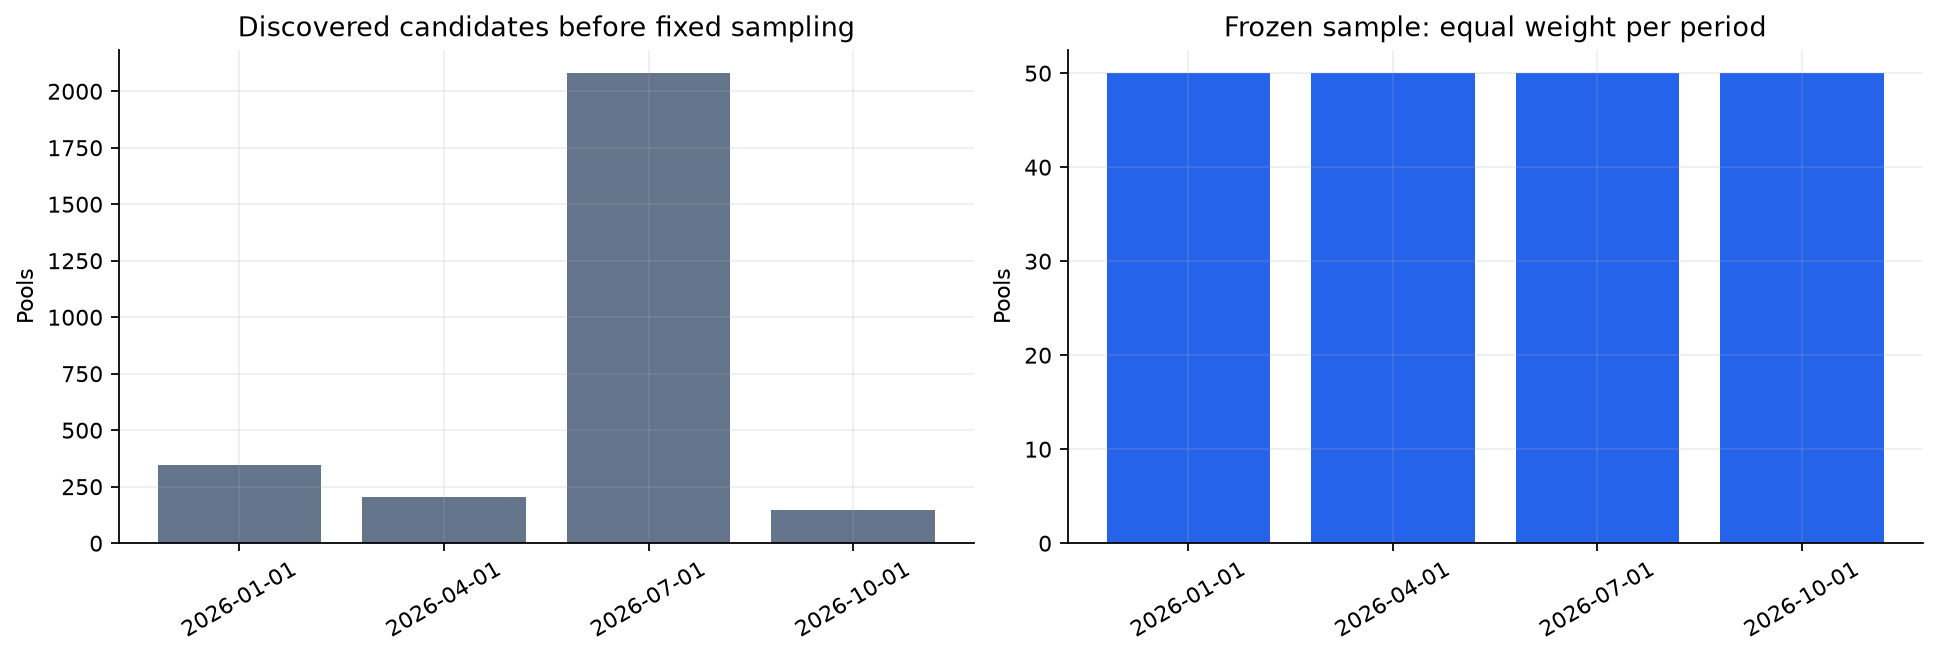

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
periods = pd.DataFrame(source_manifest["periods"])
axes[0].bar(periods.period, periods.candidates, color=COLORS[4])
axes[0].set(title="Discovered candidates before fixed sampling", ylabel="Pools")
axes[1].bar(periods.period, periods.selected, color=COLORS[0])
axes[1].set(title="Frozen sample: equal weight per period", ylabel="Pools")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
show_chart(fig, "01_selection_by_period")


## 3. Prepare targets, quality flags, and shared splits

Structural validity checks can establish that a value belongs to the requested
pool/time and can be used in the formula. They cannot independently validate
USD pricing. **Final labels remain null.** Descriptive flags such as TVL below
$1 or very large gains do not remove observations.

Split the full cohort before applying label exclusions. The embargo removes
older rows whose outcome period crosses the next split's creation boundary.
Do not move boundaries to manufacture better class counts.


In [5]:
state_lookup = {(r["pool_address"], r["endpoint"]): r for r in state_records}
assert len(state_lookup) == len(state_records)
head = source_manifest["source_metadata"]["block"]["number"]
label_records = [targets(p, state_lookup.get((p["id"], "hour24"), {}),
                         state_lookup.get((p["id"], "day8"), {}), head) for p in pools]
split_records = chronological_splits(pools)
splits = pd.DataFrame(split_records)
split_lookup = splits.set_index("pool_address")["split"].to_dict()
for row in label_records:
    row["split"] = split_lookup[row["pool_address"]]
labels = pd.DataFrame(label_records)
labels["candidate_y_class"] = pd.array(labels.candidate_y_class, dtype="Int64")
labels["candidate_y_reg_numeric"] = pd.to_numeric(labels.candidate_y_reg, errors="coerce")
assert labels.final_y_class.isna().all() and labels.final_y_reg.isna().all()
quality = labels.exclusion_reason.fillna("structurally_eligible_pricing_unverified").value_counts()
display(quality.rename("pool_count").to_frame())
display(pd.crosstab(splits.nominal_split, splits.split))
display(pd.crosstab(labels.split, labels.candidate_y_class, dropna=False))
export_table(OUTPUT, "targets", label_records)
export_table(OUTPUT, "splits", split_records)


,pool_count
exclusion_reason,
structurally_eligible_pricing_unverified,182
invalid_or_zero_hour24_tvl,10
nonexact_endpoint_timing,8


split,embargo,test,train,validation
nominal_split,,,,
test,0,30,0,0
train,40,0,100,0
validation,20,0,0,10


candidate_y_class,0,1,<NA>
split,,,
embargo,49,3,8
test,23,4,3
train,75,18,7
validation,10,0,0


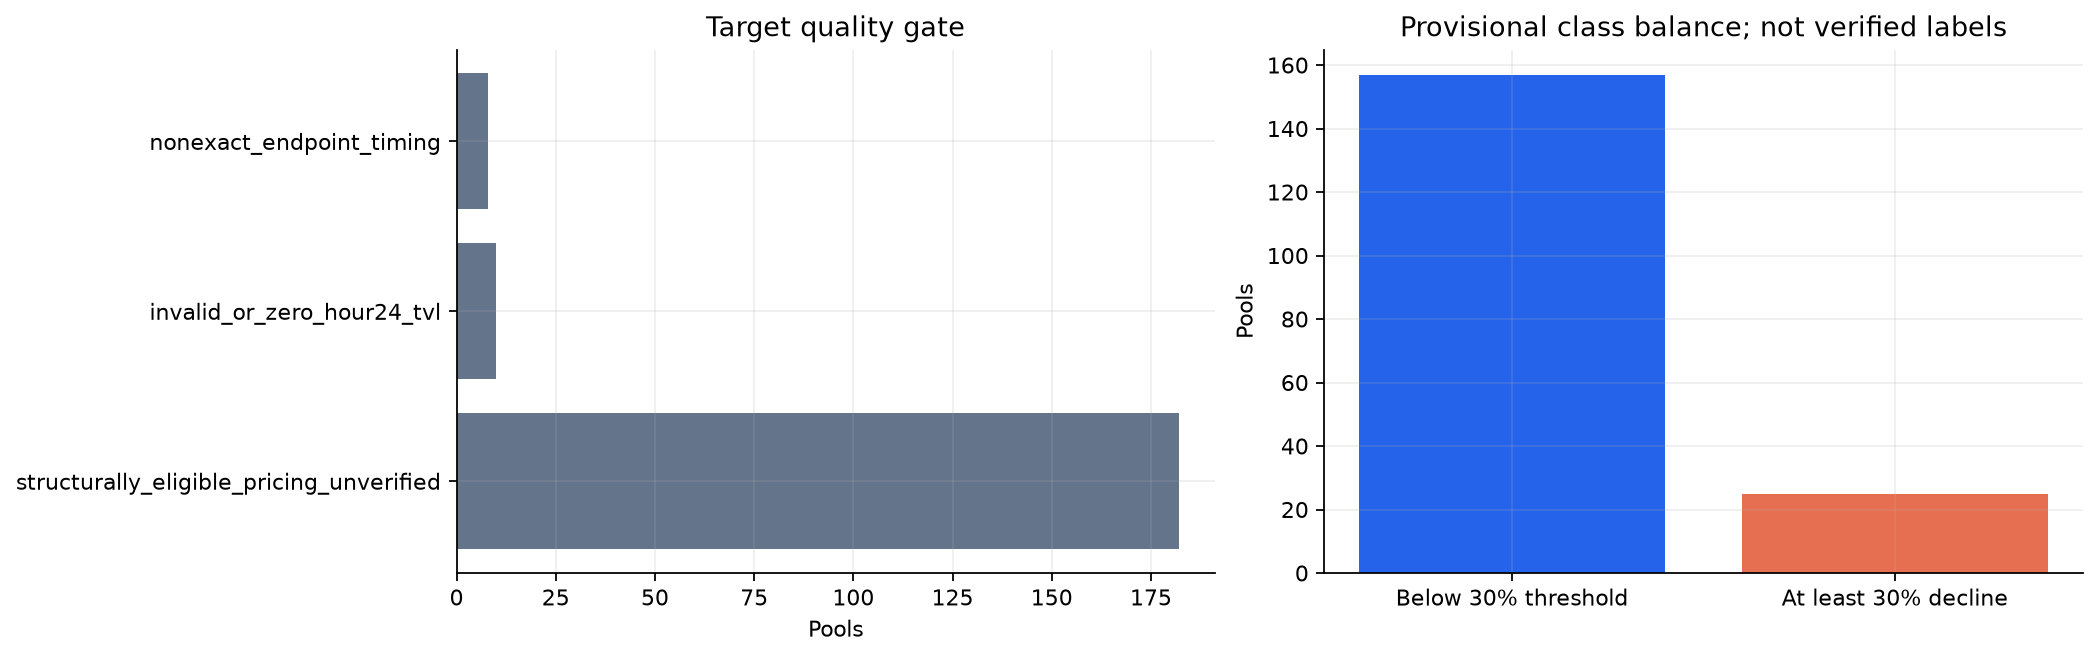

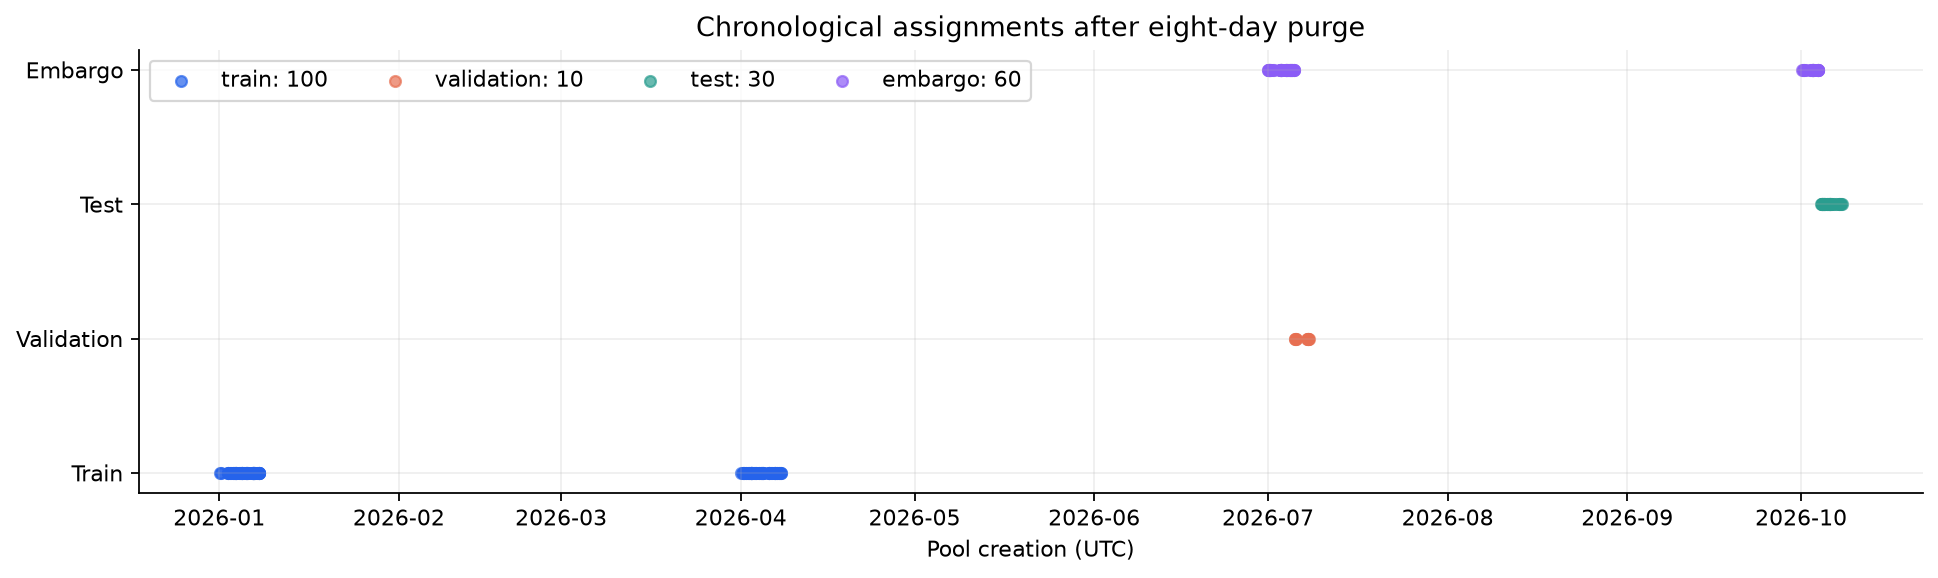

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
axes[0].barh(quality.index, quality.values, color=COLORS[4])
axes[0].set(title="Target quality gate", xlabel="Pools")
valid_counts = labels.loc[labels.structurally_eligible, "candidate_y_class"].value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["Below 30% threshold", "At least 30% decline"], valid_counts, color=[COLORS[0], COLORS[1]])
axes[1].set(title="Provisional class balance; not verified labels", ylabel="Pools")
show_chart(fig, "02_target_quality_and_class_balance")

ordered = splits.sort_values("created_at_unix")
fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
for i, (name, color) in enumerate(zip(["train", "validation", "test", "embargo"], COLORS)):
    group = ordered[ordered.split == name]
    ax.scatter(pd.to_datetime(group.created_at_unix, unit="s", utc=True), np.full(len(group), i),
               label=f"{name}: {len(group)}", color=color, alpha=.7, s=24)
ax.set(yticks=range(4), yticklabels=["Train", "Validation", "Test", "Embargo"],
       title="Chronological assignments after eight-day purge", xlabel="Pool creation (UTC)")
ax.legend(loc="upper left", ncols=4)
show_chart(fig, "03_chronological_splits")


### Split invariants and practical limits

The four separated sampling weeks make the effective split much smaller than
70/15/15. Classification validation has no positive cases; regression validation
is constant. We retain these limits instead of replacing pools or changing the
embargo. The existing cohort has already been explored, so all reported test
results remain development diagnostics.


In [7]:
for earlier, later in [("train", "validation"), ("validation", "test")]:
    a = splits.loc[splits.split == earlier, "created_at_unix"]
    b = splits.loc[splits.split == later, "created_at_unix"]
    if len(a) and len(b):
        assert a.max() + 8 * 86400 <= b.min()
features_by_window = {}
summary_lookup = {r["pool_address"]: r for r in activity_records}
for window in WINDOWS:
    rows = [feature_row(p, summary_lookup[p["id"]], window) for p in pools]
    for row in rows:
        row["split"] = split_lookup[row["pool_address"]]
    features_by_window[window] = numeric(pd.DataFrame(rows))
    export_table(OUTPUT, f"features_{window}h", rows)

eligible_labels = labels[labels.structurally_eligible].copy()
split_summary = eligible_labels.groupby("split").agg(
    pools=("pool_address", "size"), positive_candidates=("candidate_y_class", "sum"),
    regression_distinct_values=("candidate_y_reg_numeric", "nunique"))
display(split_summary)
print("Features per window:", FEATURES)
print("Missing numeric model inputs:", sum(f[NUMERIC_FEATURES].isna().sum().sum() for f in features_by_window.values()))


,pools,positive_candidates,regression_distinct_values
split,,,
embargo,52,3,11
test,27,4,14
train,93,18,29
validation,10,0,1


Features per window: ['swap_count', 'swap_transaction_count', 'active_hours', 'swap_volume_usd', 'fee_tier']
Missing numeric model inputs: 0


## 4. EDA: distinguish absent measurements from zero trading

A completed swap query with no events gives a valid indexed count of zero.
An absent hourly TVL/price entity remains an unknown measurement. These are not
the same thing. We do not fill hourly TVL or prices, remove quiet pools, invent
volatility, or use later measurements to fill early windows.

The following full-cohort plots are descriptive. Outcome-based hypothesis tests
below use training pools only, and the baseline settings are already frozen.


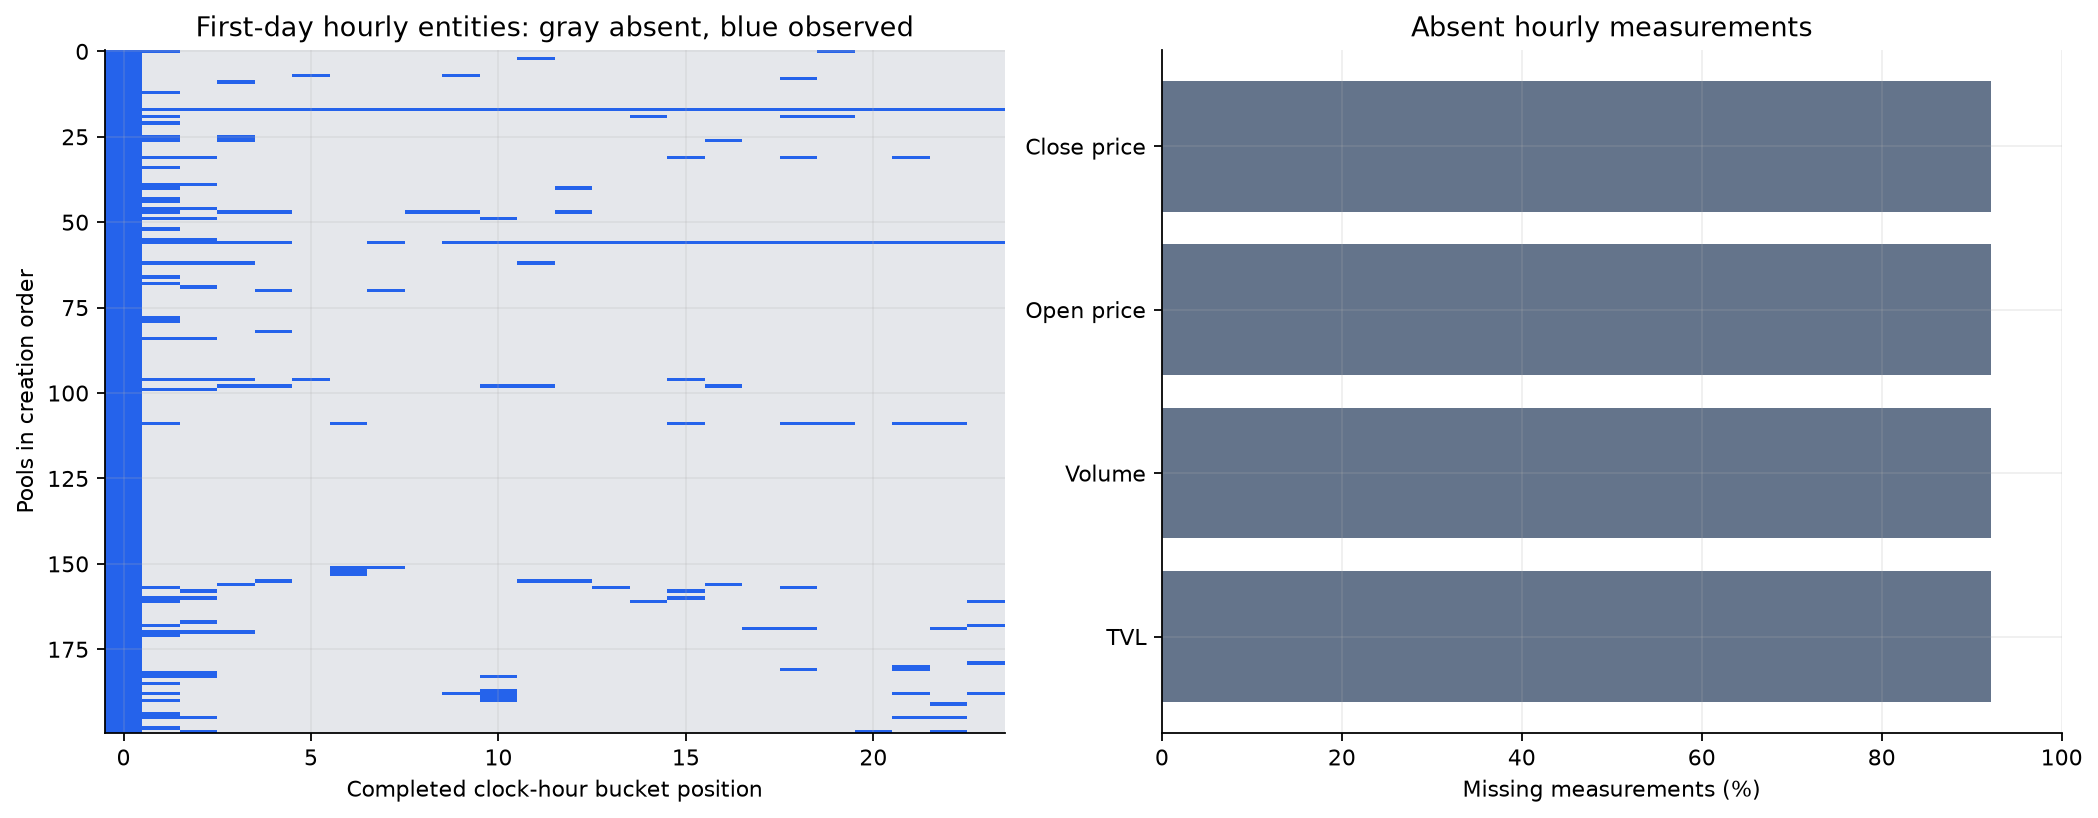

,quality,rows
0,missing,4421
1,observed,379


The creation bucket can be partial; the final partial clock-hour is excluded.


In [8]:
hourly = pd.read_csv(SOURCE / "pool_hours.csv")
assert not hourly.duplicated(["pool_address", "bucket_start_utc"]).any()
for col in ["tvlUSD", "volumeUSD", "open", "close"]:
    hourly[col] = pd.to_numeric(hourly[col], errors="coerce")
hourly["grid_position"] = hourly.groupby("pool_address").cumcount()
creation_order = pool_frame.sort_values(["created_at_unix", "pool_address"]).pool_address
coverage = hourly.assign(observed=hourly.quality.eq("observed").astype(int)).pivot(
    index="pool_address", columns="grid_position", values="observed").reindex(creation_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
image = axes[0].imshow(coverage, aspect="auto", interpolation="nearest",
    cmap=ListedColormap(["#e5e7eb", "#2563eb"]), vmin=0, vmax=1)
axes[0].set(title="First-day hourly entities: gray absent, blue observed",
    xlabel="Completed clock-hour bucket position", ylabel="Pools in creation order")
axes[1].barh(["TVL", "Volume", "Open price", "Close price"],
    hourly[["tvlUSD", "volumeUSD", "open", "close"]].isna().mean() * 100, color=COLORS[4])
axes[1].set(title="Absent hourly measurements", xlabel="Missing measurements (%)", xlim=(0, 100))
show_chart(fig, "04_hourly_measurement_missingness")
display(pd.DataFrame({"quality": hourly.quality.value_counts().index,
                      "rows": hourly.quality.value_counts().values}))
print("The creation bucket can be partial; the final partial clock-hour is excluded.")


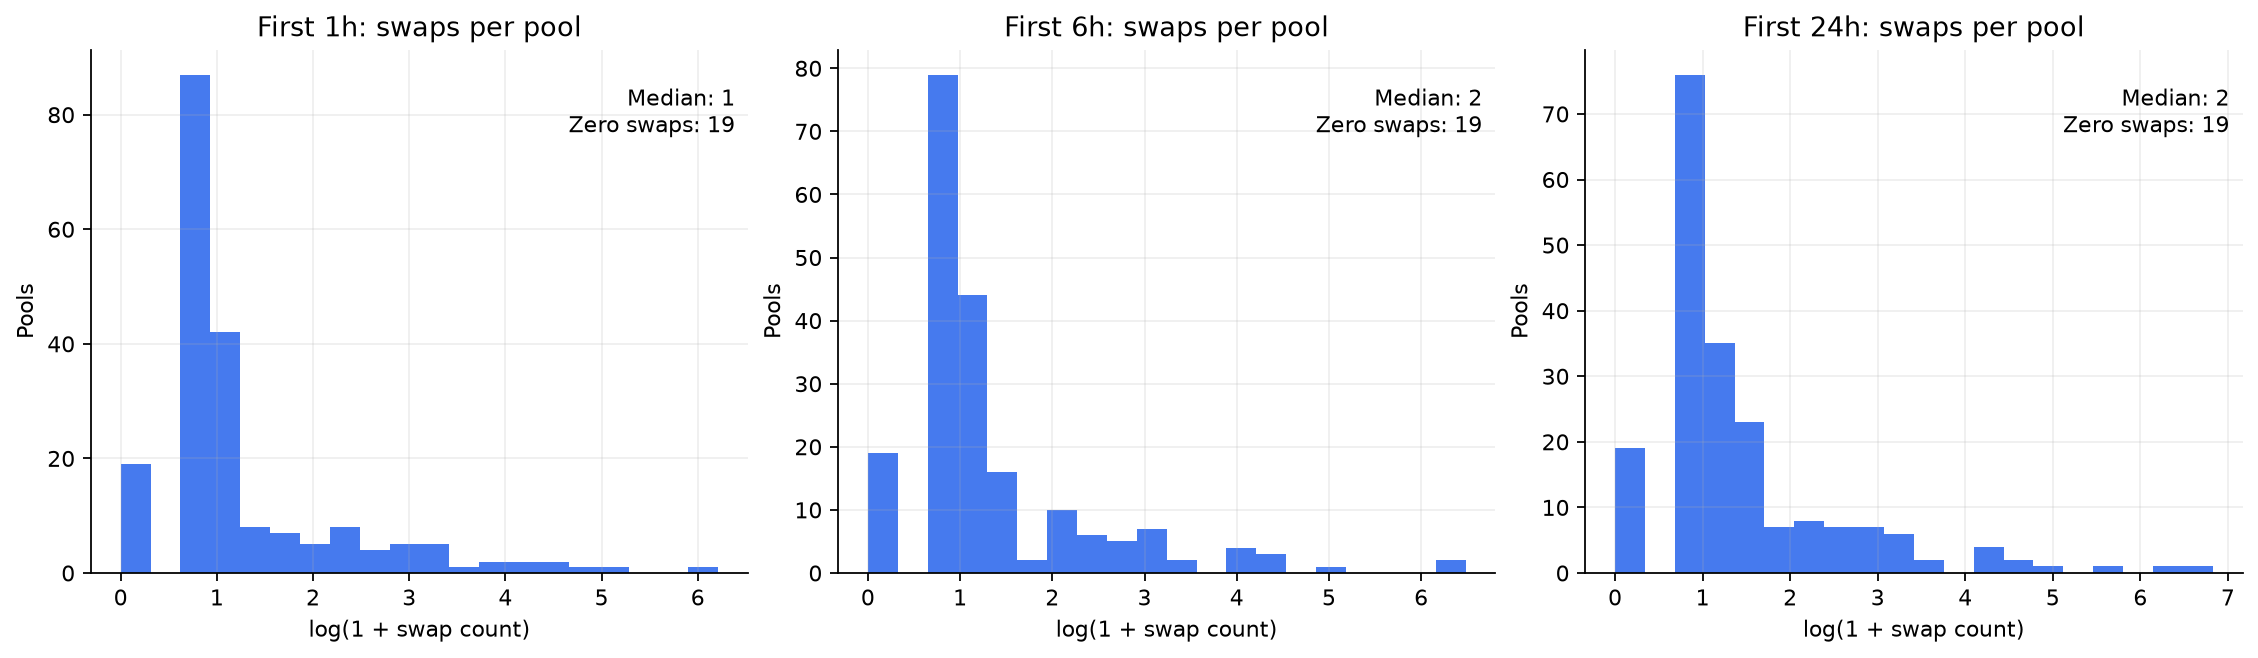

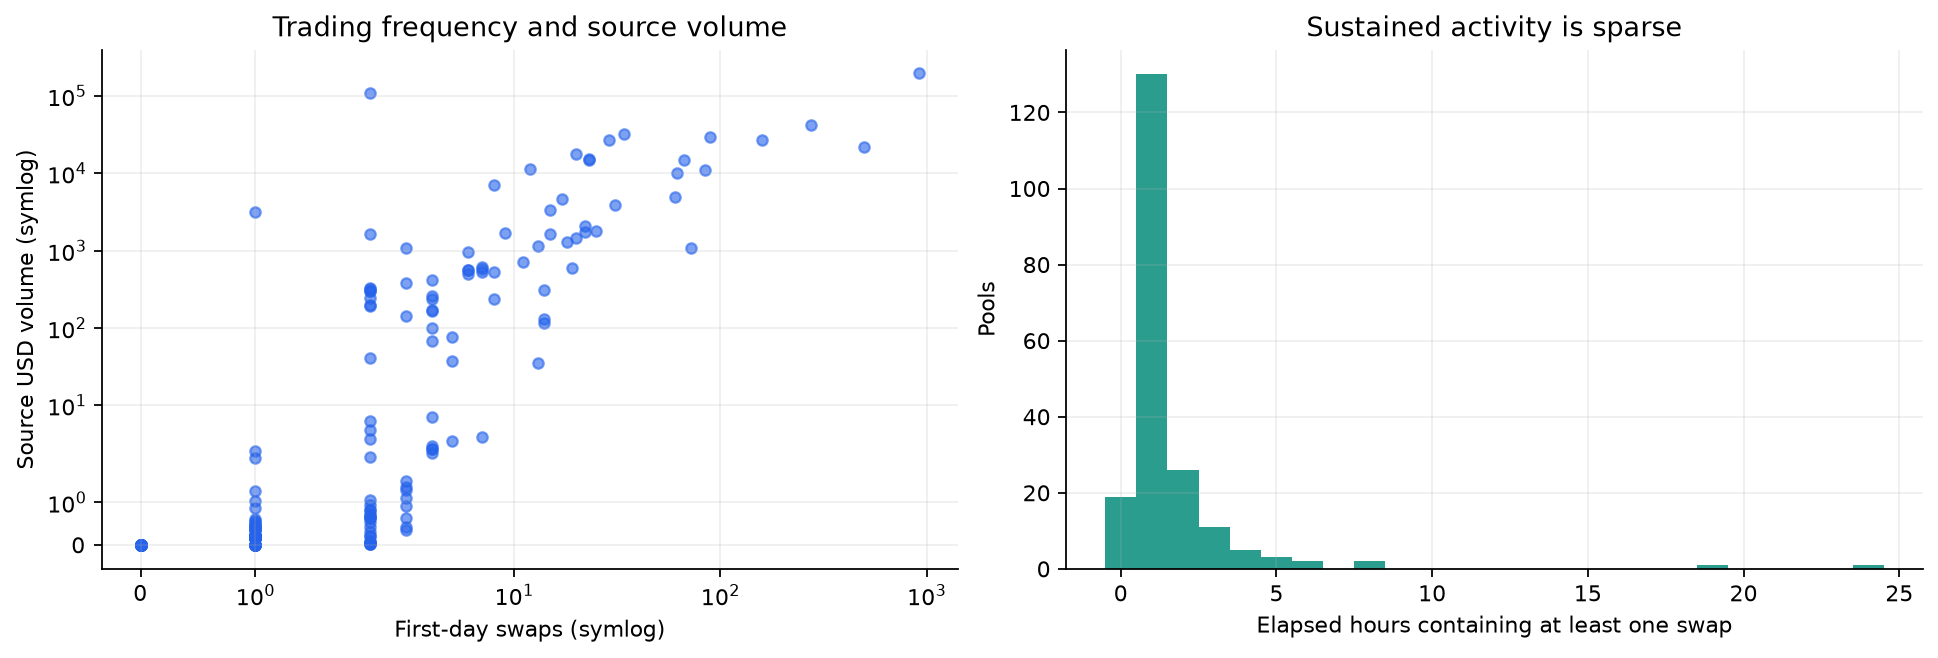

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, window in zip(axes, WINDOWS):
    values = activity[f"swap_count_{window}h"].astype(float)
    ax.hist(np.log1p(values), bins=20, color=COLORS[0], alpha=.85)
    ax.set(title=f"First {window}h: swaps per pool", xlabel="log(1 + swap count)", ylabel="Pools")
    ax.text(.98, .93, f"Median: {values.median():g}\nZero swaps: {(values == 0).sum()}",
            transform=ax.transAxes, ha="right", va="top")
show_chart(fig, "05_swap_distributions_by_window")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
f24 = features_by_window[24]
axes[0].scatter(f24.swap_count, f24.swap_volume_usd, s=22, alpha=.6, color=COLORS[0])
axes[0].set(xscale="symlog", yscale="symlog", xlabel="First-day swaps (symlog)",
    ylabel="Source USD volume (symlog)", title="Trading frequency and source volume")
axes[1].hist(f24.active_hours, bins=np.arange(-.5, 25.5), color=COLORS[2])
axes[1].set(xlabel="Elapsed hours containing at least one swap", ylabel="Pools", title="Sustained activity is sparse")
show_chart(fig, "06_volume_and_active_hours")


### Do days 2 and 3 solve the sparsity problem?

This is the separately approved descriptive comparison of the **same** pools.
Day-2/day-3 variables are never added to the first-1h/6h/24h model inputs.
Show daily increments separately from cumulative counts; cumulative growth alone
is not evidence that a typical pool becomes more active.


,swaps,volume_usd,zero_swap_pools,pools_at_least_10_swaps,median_swaps
day,,,,,
1,3041,633141.770597,19,32,2.0
2,1023,226878.751231,177,2,0.0
3,2547,578486.572287,180,2,0.0


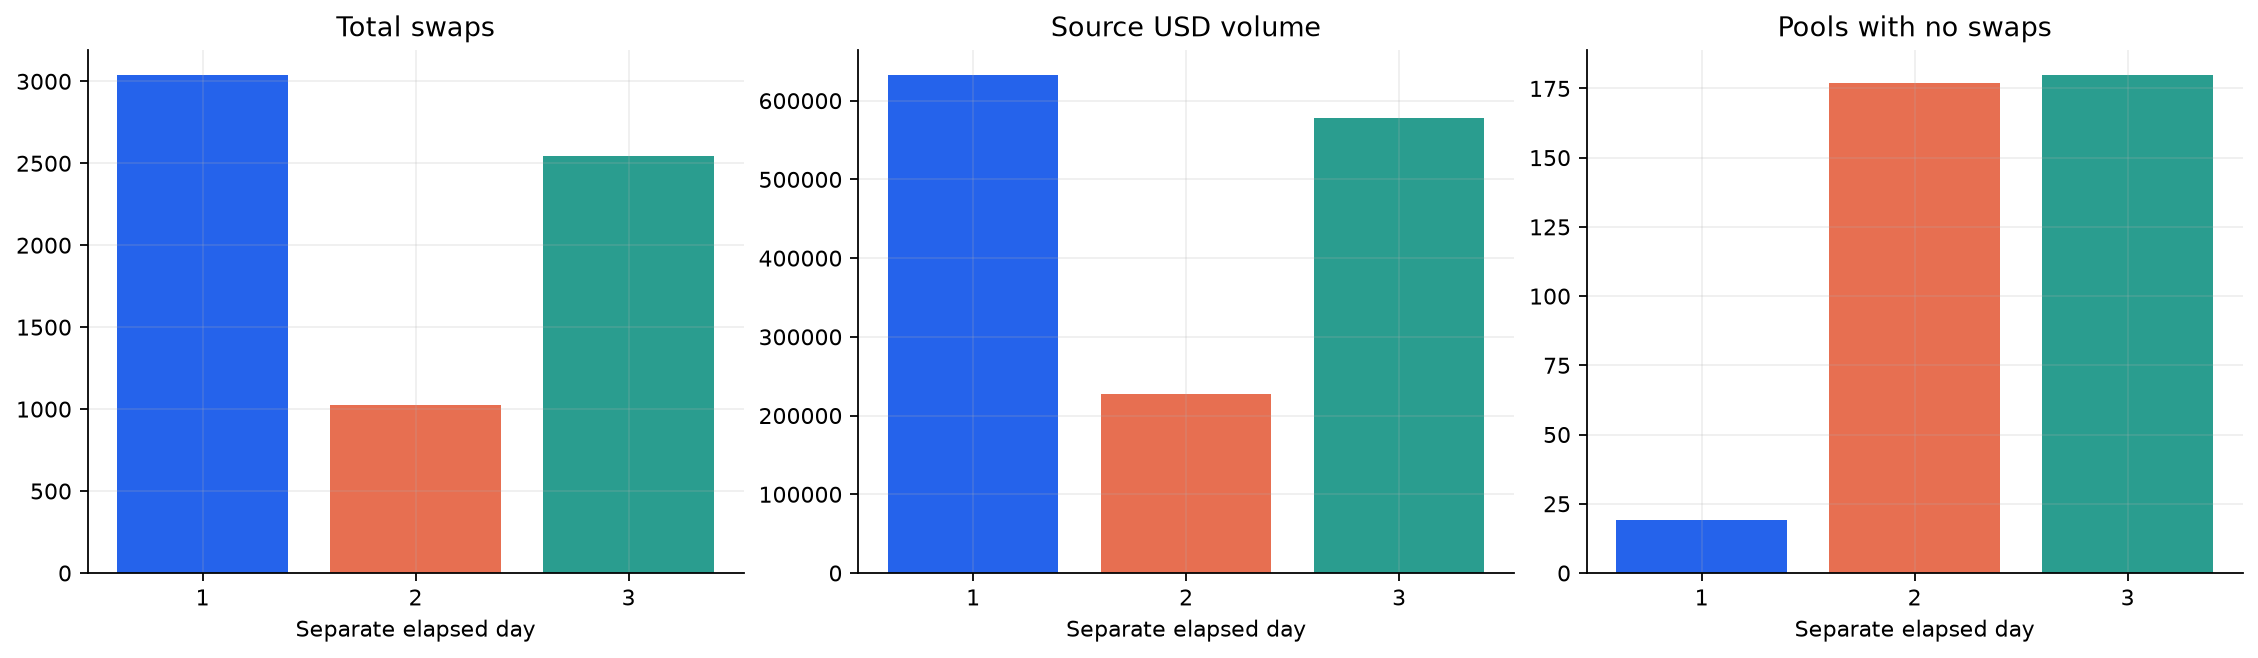

Largest pool's share of day-3 swaps: 86.9%


In [10]:
daily_path = SOURCE / "three_day_activity/daily_activity.csv"
if daily_path.exists():
    daily = pd.read_csv(daily_path)
    assert not daily.duplicated(["pool_address", "day"]).any()
    daily["volume_usd"] = pd.to_numeric(daily.volume_usd)
    daily_summary = daily.groupby("day").agg(swaps=("swap_count", "sum"),
        volume_usd=("volume_usd", "sum"), zero_swap_pools=("swap_count", lambda s: int((s == 0).sum())),
        pools_at_least_10_swaps=("swap_count", lambda s: int((s >= 10).sum())),
        median_swaps=("swap_count", "median"))
    display(daily_summary)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, col, title in zip(axes, ["swaps", "volume_usd", "zero_swap_pools"],
                             ["Total swaps", "Source USD volume", "Pools with no swaps"]):
        ax.bar(daily_summary.index, daily_summary[col], color=COLORS[:3])
        ax.set(title=title, xlabel="Separate elapsed day", xticks=[1, 2, 3])
    show_chart(fig, "07_separate_three_day_activity")
    day3 = daily[daily.day == 3].sort_values("swap_count", ascending=False)
    total = day3.swap_count.sum()
    print(f"Largest pool's share of day-3 swaps: {100 * day3.iloc[0].swap_count / total:.1f}%" if total else "No day-3 swaps")
else:
    display(Markdown("Three-day cache unavailable. This optional diagnostic is skipped without a network call."))


### Target distribution and tiny denominators

The regression target is signed percentage change, not dollar loss or predicted
TVL. A tiny starting value can produce an enormous percentage change. We flag
and inspect these cases; we do not trim them to improve scores. Both views below
include all structurally eligible targets. A symlog axis makes the tail visible
without deleting or clipping observations.


,hour24_tvl_numeric,day8_tvl_numeric,candidate_y_reg_numeric
count,1.820000e+02,1.820000e+02,182.000000
mean,7.711436e+02,7.575469e+01,357.786329
std,8.130054e+03,5.212436e+02,4780.957082
min,2.141931e-15,2.141931e-15,-100.000000
25%,1.855061e-01,1.828201e-01,0.000000
50%,4.509162e-01,3.778179e-01,0.000000
75%,4.839027e+00,3.209071e+00,0.000000
95%,2.014661e+02,1.365822e+02,108.142411
99%,8.600631e+03,2.665083e+03,403.717533
max,1.077515e+05,5.601288e+03,64495.767140


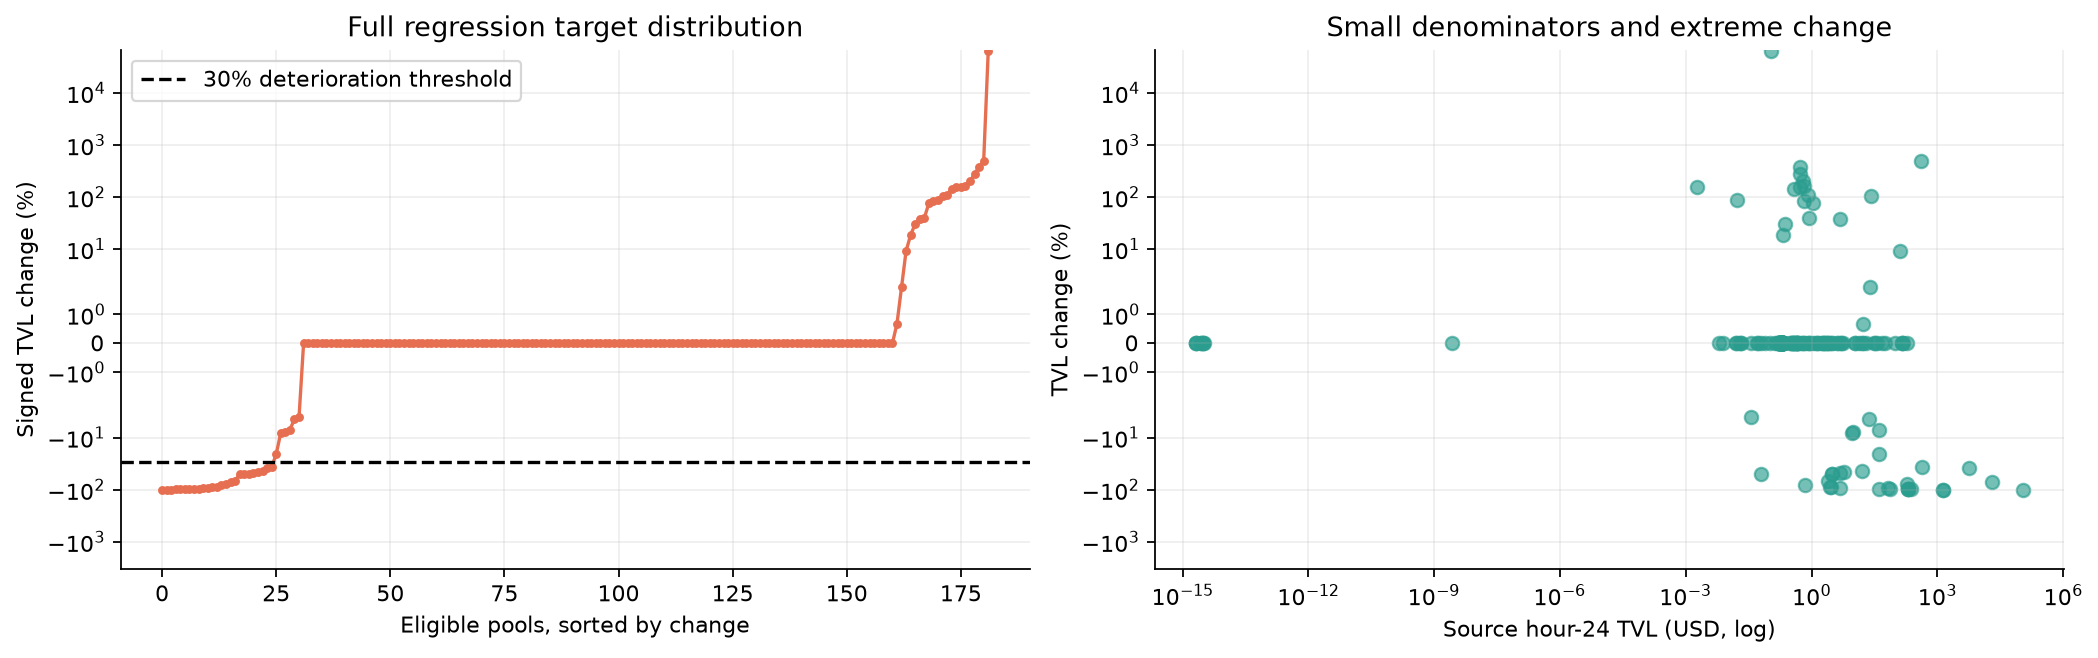

,pool_address,hour24_tvl_usd,day8_tvl_usd,candidate_y_reg,audit_flags
42,0xdfaf5e69c96904d102fcaaa7a701b401263a9ef4,0.1052985520047499521168707516084772,68.01840745501139118272280044415833,64495.7671402196709922820541857313868568922501...,"[hour24_tvl_below_one_usd_descriptive_only, ga..."
112,0x40b849de567756149d5e290cbd044a3d3cca4578,414.3234429162442861997688985025216,2461.821517138201040348665361678129,494.178668677422538590979700880236037047992604...,[]
188,0x21d670a67a70e6fa662bd31ee96d2b0168956e38,0.5199112751011752256454468808227325,2.508562825701229657076702418507975,382.498254190209850645077035971340621885125943...,[hour24_tvl_below_one_usd_descriptive_only]
187,0xe959e9a980541c75c75fa81950b3dab5e4154aad,0.5402850709878779632743466037636737,2.020922043653477904123193420113043,274.047359842526550665073142863839718915827447...,[hour24_tvl_below_one_usd_descriptive_only]
73,0xbfd4567fc43be04fb2b6cae4b4727a6b3603a914,0.6154913762752240039793962767388419,1.858826886815352291849837392367242,202.006974990362269996177561411499072749403260...,[hour24_tvl_below_one_usd_descriptive_only]


In [11]:
valid = labels[labels.structurally_eligible].copy()
valid["hour24_tvl_numeric"] = pd.to_numeric(valid.hour24_tvl_usd)
valid["day8_tvl_numeric"] = pd.to_numeric(valid.day8_tvl_usd)
display(valid[["hour24_tvl_numeric", "day8_tvl_numeric", "candidate_y_reg_numeric"]].describe(
    percentiles=[.25, .5, .75, .95, .99]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ordered_change = valid.candidate_y_reg_numeric.sort_values().to_numpy()
axes[0].plot(np.arange(len(ordered_change)), ordered_change, marker=".", color=COLORS[1])
axes[0].axhline(-30, linestyle="--", color="black", label="30% deterioration threshold")
axes[0].set(yscale="symlog", xlabel="Eligible pools, sorted by change", ylabel="Signed TVL change (%)",
            title="Full regression target distribution")
axes[0].legend()
axes[1].scatter(valid.hour24_tvl_numeric, valid.candidate_y_reg_numeric, color=COLORS[2], alpha=.65)
axes[1].set(xscale="log", yscale="symlog", xlabel="Source hour-24 TVL (USD, log)",
            ylabel="TVL change (%)", title="Small denominators and extreme change")
show_chart(fig, "08_targets_and_small_denominators")
display(valid.nlargest(5, "candidate_y_reg_numeric")[["pool_address", "hour24_tvl_usd", "day8_tvl_usd", "candidate_y_reg", "audit_flags"]])


## 5. Training-only DS comparisons

Use Mann–Whitney U for continuous activity variables and chi-square for fee-tier
categories. These are exploratory associations with **provisional** outcome
groups, not causes. Report sample counts, medians, rank-biserial effects, and
Bonferroni-adjusted p-values across the prespecified family. Fee-tier chi-square
p-values are withheld if observed/expected cell counts are too small; categories
are not regrouped to manufacture significance.

Only training pools enter these tests. Fixed model settings above are not
changed based on significance. Temporal dependence, sparse observations, small
samples, and unverified valuations limit inference.


,window_hours,feature,positive_n,negative_n,positive_median,negative_median,u_statistic,rank_biserial_positive_higher,p_value,method,scope,family_size,p_bonferroni
0,1,swap_count,18,75,6.00000,2.000000,1043.5,0.545926,0.000232,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.002787
1,1,swap_transaction_count,18,75,6.00000,2.000000,1043.5,0.545926,0.000232,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.002787
2,1,active_hours,18,75,1.00000,1.000000,682.5,0.011111,0.872910,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,1.000000
3,1,swap_volume_usd,18,75,544.21616,0.689263,1095.5,0.622963,0.000044,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.000529
4,6,swap_count,18,75,6.50000,2.000000,1043.0,0.545185,0.000262,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.003139
5,6,swap_transaction_count,18,75,6.50000,2.000000,1042.0,0.543704,0.000272,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.003263
6,6,active_hours,18,75,1.00000,1.000000,835.5,0.237778,0.048589,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.583062
7,6,swap_volume_usd,18,75,563.13452,0.826145,1095.5,0.622963,0.000044,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.000529
8,24,swap_count,18,75,6.50000,2.000000,1019.0,0.509630,0.000670,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.008043
9,24,swap_transaction_count,18,75,6.50000,2.000000,1019.0,0.509630,0.000670,two_sided_mann_whitney_u_asymptotic_tie_and_co...,training_only_provisional_outcome_groups,12,0.008043


,window_hours,feature,n,chi2,degrees_of_freedom,cramers_v,p_value,minimum_expected_count,assumptions_supported,reason,scope,family_size,p_bonferroni
0,1,fee_tier,93,15.519375,3,0.408503,None,1.548387,False,sparse_cells_inferential_p_value_withheld,training_only_provisional_outcome_groups,3,None
1,6,fee_tier,93,15.519375,3,0.408503,None,1.548387,False,sparse_cells_inferential_p_value_withheld,training_only_provisional_outcome_groups,3,None
2,24,fee_tier,93,15.519375,3,0.408503,None,1.548387,False,sparse_cells_inferential_p_value_withheld,training_only_provisional_outcome_groups,3,None


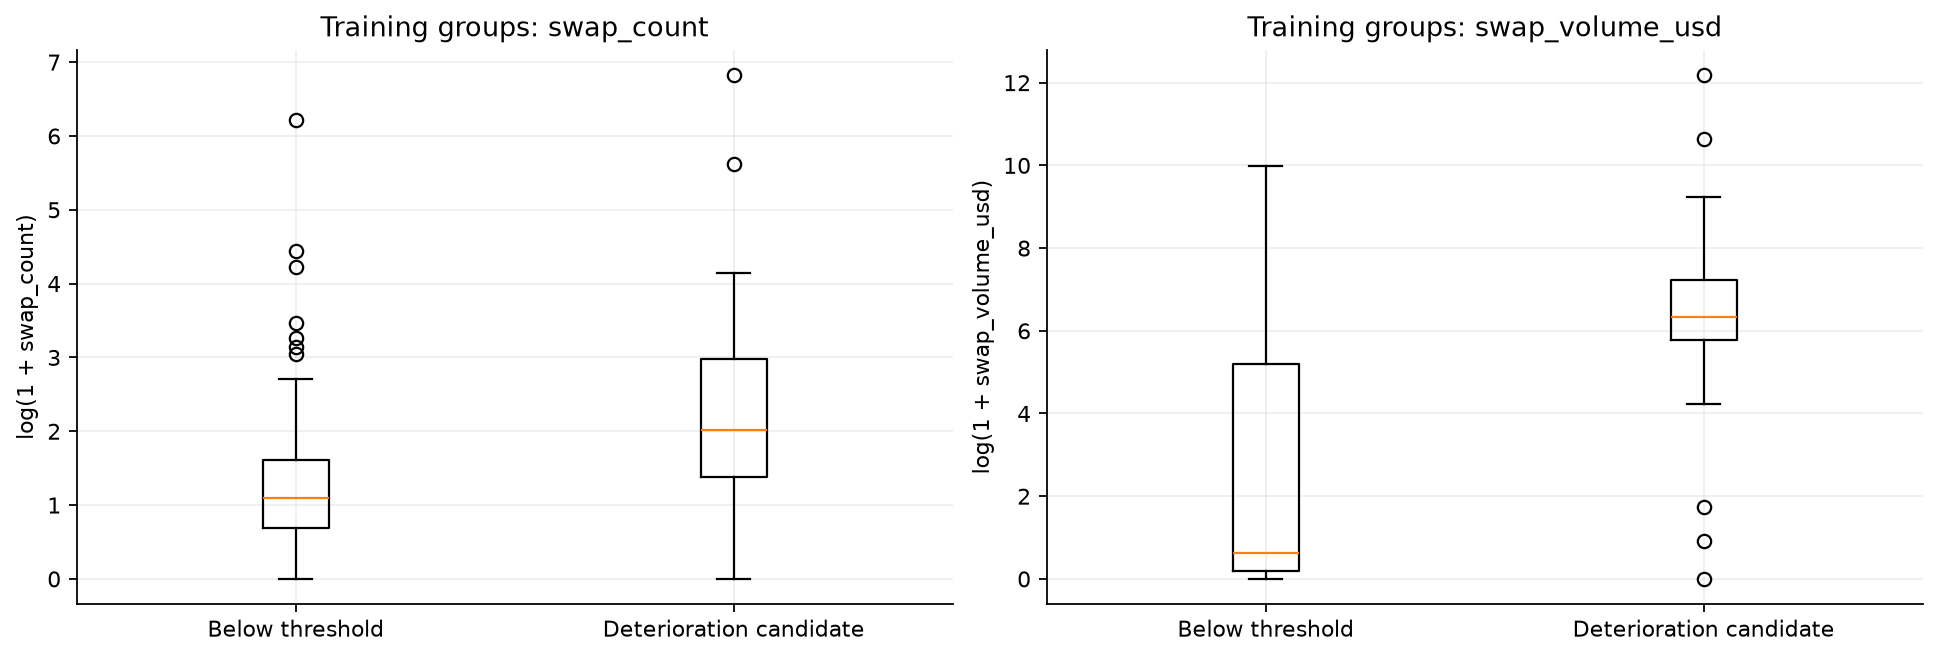

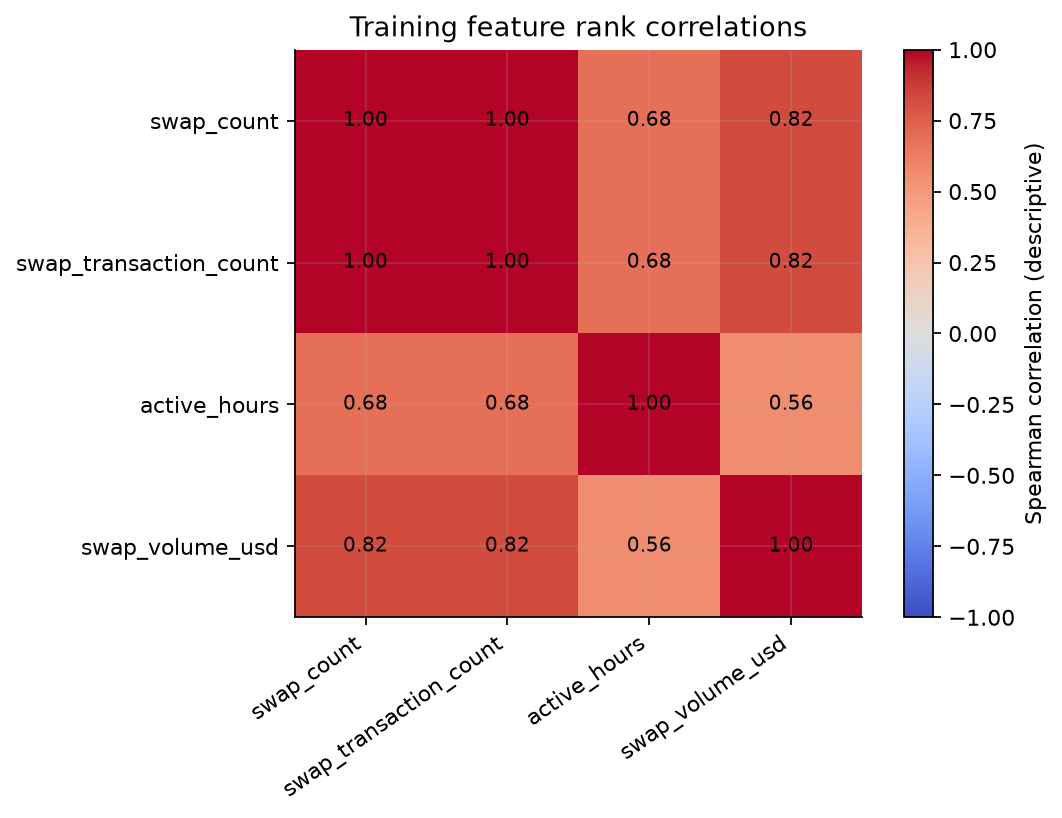

In [12]:
mann_whitney, chi_square = training_tests(features_by_window, labels)
display(mann_whitney)
display(chi_square.drop(columns=["observed_table"]))
mann_whitney.to_csv(OUTPUT / "mann_whitney_training.csv", index=False)
chi_square.to_csv(OUTPUT / "chi_square_training.csv", index=False)

training24 = features_by_window[24].query("split == 'train' and feature_eligible").merge(
    labels[["pool_address", "candidate_y_class", "structurally_eligible"]], on="pool_address", validate="one_to_one")
training24 = training24[training24.structurally_eligible]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, feature in zip(axes, ["swap_count", "swap_volume_usd"]):
    values = [np.log1p(training24.loc[training24.candidate_y_class == label, feature].astype(float)) for label in [0, 1]]
    ax.boxplot(values, tick_labels=["Below threshold", "Deterioration candidate"], showfliers=True)
    ax.set(title=f"Training groups: {feature}", ylabel=f"log(1 + {feature})")
show_chart(fig, "09_training_outcome_group_comparisons")

correlation = training24[NUMERIC_FEATURES].astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set(xticks=range(len(NUMERIC_FEATURES)), yticks=range(len(NUMERIC_FEATURES)),
    xticklabels=NUMERIC_FEATURES, yticklabels=NUMERIC_FEATURES, title="Training feature rank correlations")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
for i in range(len(NUMERIC_FEATURES)):
    for j in range(len(NUMERIC_FEATURES)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Spearman correlation (descriptive)")
show_chart(fig, "10_training_feature_correlations")


## 6. Preprocessing: show the actual transformations

All five chosen features are observed/available, so no imputer is used. Counts
and source USD volume use fixed `log1p`; a scaler learns means/scales from
training pools only. Fee tier is one-hot encoded using training categories.
The exported raw features still contain the original numbers. Identifiers,
future outcomes, target-quality flags, and later windows are excluded from X.

The following displays the exact shared implementation used by the CLI and the
notebook. Keeping pure reusable functions in `src/` avoids two different versions
of the experiment; the notebook shows and executes every modeling stage.


In [13]:
display(Code(inspect.getsource(preprocessor), language="python"))
display(Code(inspect.getsource(fit_baseline), language="python"))
training_rows = features_by_window[24].query("split == 'train' and feature_eligible").merge(
    labels[["pool_address", "structurally_eligible"]], on="pool_address", validate="one_to_one")
training_rows = training_rows[training_rows.structurally_eligible]
x_demo = training_rows[FEATURES]
demo_processor = preprocessor().fit(x_demo)  # No validation/test rows are passed here.
transformed_demo = demo_processor.transform(x_demo)
transformed_names = demo_processor.get_feature_names_out()
display(x_demo.head())
display(pd.DataFrame(transformed_demo, columns=transformed_names).head())
scaler = demo_processor.named_transformers_["numeric"].named_steps["scale"]
np.testing.assert_allclose(scaler.mean_, np.log1p(x_demo[NUMERIC_FEATURES]).mean(axis=0))
print("Verified training-only scaler means; transformed width:", len(transformed_names))


def preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ("numeric", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                               ("scale", StandardScaler())]), NUMERIC_FEATURES),
        ("fee", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ])

def fit_baseline(task: str, name: str, x_train: pd.DataFrame, y_train: np.ndarray) -> Pipeline:
    estimators = {
        "dummy_prior": DummyClassifier(strategy="prior"),
        "logistic_regression": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=42),
        "dummy_mean": DummyRegressor(strategy="mean"),
        "dummy_median": DummyRegressor(strategy="median"),
        "ridge": Ridge(alpha=1.0),
    }
    if list(x_train.columns) != FEATURES:
        raise DemoError("Feature order does not match the versioned contract.")
    if task == "classification" and len(np.unique(y_train)) != 2:
        raise DemoError("Classification training requires both classes.")
    pipeline = Pipeline([("preprocess", preprocessor()), ("model", clone(estimators[name]))])
    pipeline.fit(x_train, y_train)
    return pipeline

,swap_count,swap_transaction_count,active_hours,swap_volume_usd,fee_tier
0,25.0,25.0,3.0,1788.131884,10000
1,499.0,499.0,1.0,21569.020806,10000
2,84.0,84.0,1.0,11138.275580,10000
3,67.0,67.0,2.0,14894.462142,10000
4,2.0,2.0,1.0,324.240606,10000


,numeric__swap_count,numeric__swap_transaction_count,numeric__active_hours,numeric__swap_volume_usd,fee__fee_tier_100,fee__fee_tier_10000,fee__fee_tier_3000,fee__fee_tier_500
0,1.328825,1.341526,1.046814,1.298077,0.0,1.0,0.0,0.0
1,3.660510,3.692019,-0.318931,2.055202,0.0,1.0,0.0,0.0
2,2.263037,2.283273,-0.318931,1.854232,0.0,1.0,0.0,0.0
3,2.087053,2.105869,0.479979,1.942602,0.0,1.0,0.0,0.0
4,-0.374275,-0.375312,-0.318931,0.779579,0.0,1.0,0.0,0.0


Verified training-only scaler means; transformed width: 8


## 7. Train the fixed baselines

Classification: Dummy prior probability versus Logistic Regression (`C=1`,
balanced training class weights, fixed 0.5 threshold). Regression: mean/median
Dummy versus Ridge (`alpha=1`). Raw percentage-change targets are not clipped or
log-transformed. No tuning, resampling, calibration, or winner selection occurs.

The loop passes **only training X/y** into fitting, then scores validation and
test rows separately. Both tasks and all windows reuse the same pool split.


In [14]:
if not ALLOW_PROVISIONAL_TARGETS:
    raise RuntimeError("This notebook trains experimental models; explicitly enable provisional targets to continue.")
assert CONFIG == frozen_config, "Experiment configuration changed after EDA. Restart before fitting."
fitted_models, metric_rows, prediction_rows = {}, [], []
label_index = labels.set_index("pool_address")
for window in WINDOWS:
    frame = features_by_window[window].merge(
        labels[["pool_address", "structurally_eligible", "candidate_y_class", "candidate_y_reg_numeric"]],
        on="pool_address", validate="one_to_one")
    frame = frame[frame.feature_eligible & frame.structurally_eligible & frame.split.ne("embargo")]
    train = frame[frame.split == "train"]
    print(f"{window}h: {len(train)} training pools; positive candidates = {int(train.candidate_y_class.sum())}")
    for task, names, target in [("classification", ["dummy_prior", "logistic_regression"], "candidate_y_class"),
                                ("regression", ["dummy_mean", "dummy_median", "ridge"], "candidate_y_reg_numeric")]:
        y_train = train[target].to_numpy(dtype=int if task == "classification" else float)
        if len(train) < 2 or (task == "classification" and len(np.unique(y_train)) < 2):
            print("Skipped unsupported training task:", window, task)
            continue
        for name in names:
            fitted = fit_baseline(task, name, train[FEATURES], y_train)
            fitted_models[(window, name)] = fitted
            model_version = f"baseline_v1_{window}h_{name}_{input_hashes['pools.json'][:12]}"
            joblib.dump({"pipeline": fitted, "window_hours": window, "task": task, "features": FEATURES,
                         "model_version": model_version, "configuration": frozen_config,
                         "status": "experimental_provisional_usd_targets", "input_sha256": input_hashes},
                        OUTPUT / "models" / f"{window}h_{name}.joblib")
            for split in ["validation", "test"]:
                held = frame[frame.split == split]
                if held.empty:
                    print("No eligible evaluation rows:", window, task, split)
                    continue
                actual = held[target].to_numpy(dtype=int if task == "classification" else float)
                predicted = fitted.predict_proba(held[FEATURES])[:, 1] if task == "classification" else fitted.predict(held[FEATURES])
                measured = classification_metrics(actual, predicted) if task == "classification" else regression_metrics(actual, predicted)
                metric_rows.append({"window_hours": window, "task": task, "model": name, "model_version": model_version,
                                    "split": split, "status": "experimental_provisional_targets", **measured})
                for pool_id, truth, prediction in zip(held.pool_address, actual, predicted):
                    prediction_rows.append({"pool_address": pool_id, "window_hours": window, "task": task,
                        "model": name, "model_version": model_version, "split": split,
                        "observed_provisional_target": float(truth),
                        "classification_score": float(prediction) if task == "classification" else None,
                        "predicted_class": int(prediction >= .5) if task == "classification" else None,
                        "predicted_tvl_change_pct": float(prediction) if task == "regression" else None,
                        "classification_definition_version": CLASS_VERSION, "regression_definition_version": REG_VERSION,
                        "target_quality": "provisional_usd_valuation", "evaluation_status": CONFIG["evaluation_status"]})
metrics = pd.DataFrame(metric_rows)
predictions = pd.DataFrame(prediction_rows)
assert metrics.shape[0] == 30 and len(fitted_models) == 15
assert len(predictions) == 555
print(f"Saved {len(fitted_models)} models, {len(metrics)} evaluation records, {len(predictions)} predictions.")
export_table(OUTPUT, "predictions", prediction_rows)
metrics_export = [{**r, "confusion_matrix": json.dumps(r["confusion_matrix"]) if "confusion_matrix" in r else None} for r in metric_rows]
export_table(OUTPUT, "metrics", metrics_export)


1h: 93 training pools; positive candidates = 18
6h: 93 training pools; positive candidates = 18


24h: 93 training pools; positive candidates = 18
Saved 15 models, 30 evaluation records, 555 predictions.


## 8. Classification results and charts

This test partition contains only four positive candidates. One detected event
changes recall by 25 percentage points. Scores are uncalibrated. Show false
alarms and missed events alongside ranking metrics; a high majority accuracy
would be misleading.

PR-AUC here is trapezoidal area, while Average Precision is reported separately.
Constant scores can have surprisingly large trapezoidal PR-AUC because of
interpolation endpoints; do not confuse that with strong detection.


,window_hours,model,n,positive_count,f1,precision,recall,pr_auc,average_precision,roc_auc,brier_score
1,1,dummy_prior,27,4.0,0.000000,0.000000,0.00,0.574074,0.148148,0.500000,0.128261
3,1,logistic_regression,27,4.0,0.117647,0.076923,0.25,0.339806,0.366368,0.423913,0.395009
11,6,dummy_prior,27,4.0,0.000000,0.000000,0.00,0.574074,0.148148,0.500000,0.128261
13,6,logistic_regression,27,4.0,0.111111,0.071429,0.25,0.329555,0.353486,0.336957,0.413061
21,24,dummy_prior,27,4.0,0.000000,0.000000,0.00,0.574074,0.148148,0.500000,0.128261
23,24,logistic_regression,27,4.0,0.111111,0.071429,0.25,0.328279,0.351852,0.326087,0.396824


,window_hours,model,positive_count,f1,roc_auc,metric_warning
0,1,dummy_prior,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...
2,1,logistic_regression,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...
10,6,dummy_prior,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...
12,6,logistic_regression,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...
20,24,dummy_prior,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...
22,24,logistic_regression,0.0,NaN,NaN,single_class_evaluation_no_discrimination_or_p...


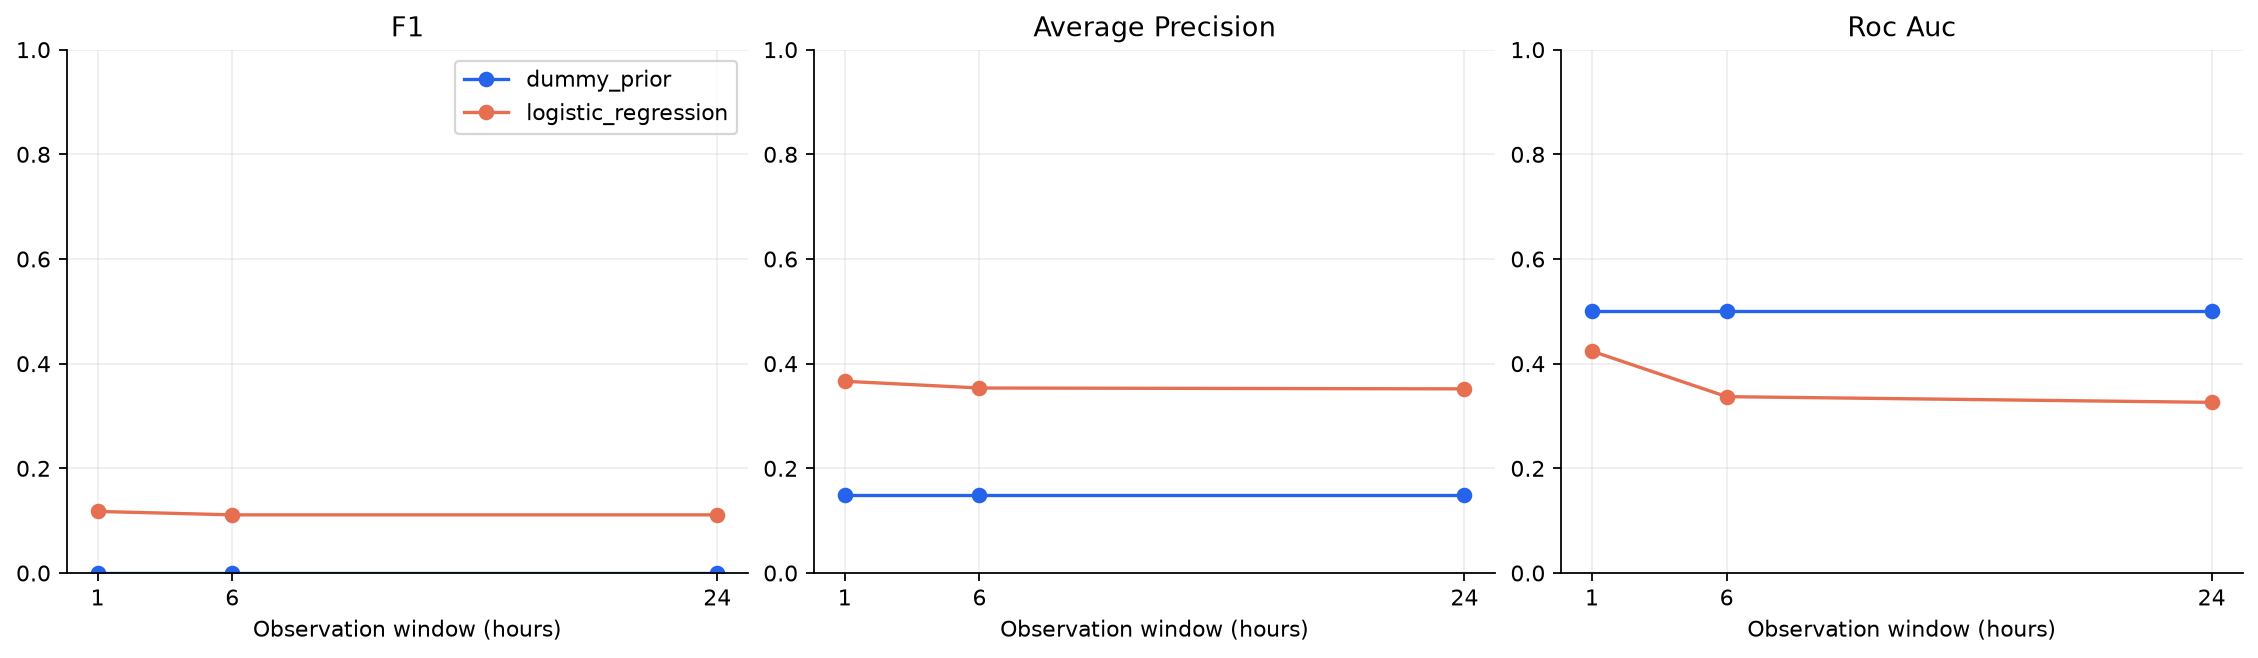

In [15]:
classification = metrics[(metrics.task == "classification") & (metrics.split == "test")]
display(classification[["window_hours", "model", "n", "positive_count", "f1", "precision", "recall",
                        "pr_auc", "average_precision", "roc_auc", "brier_score"]])
display(metrics[(metrics.task == "classification") & (metrics.split == "validation")][
    ["window_hours", "model", "positive_count", "f1", "roc_auc", "metric_warning"]])
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, measure in zip(axes, ["f1", "average_precision", "roc_auc"]):
    for name, color in zip(["dummy_prior", "logistic_regression"], COLORS):
        group = classification[classification.model == name]
        ax.plot(group.window_hours, group[measure], marker="o", label=name, color=color)
    ax.set(title=measure.replace("_", " ").title(), xlabel="Observation window (hours)", xticks=WINDOWS, ylim=(0, 1))
axes[0].legend()
show_chart(fig, "11_classification_metric_comparison")


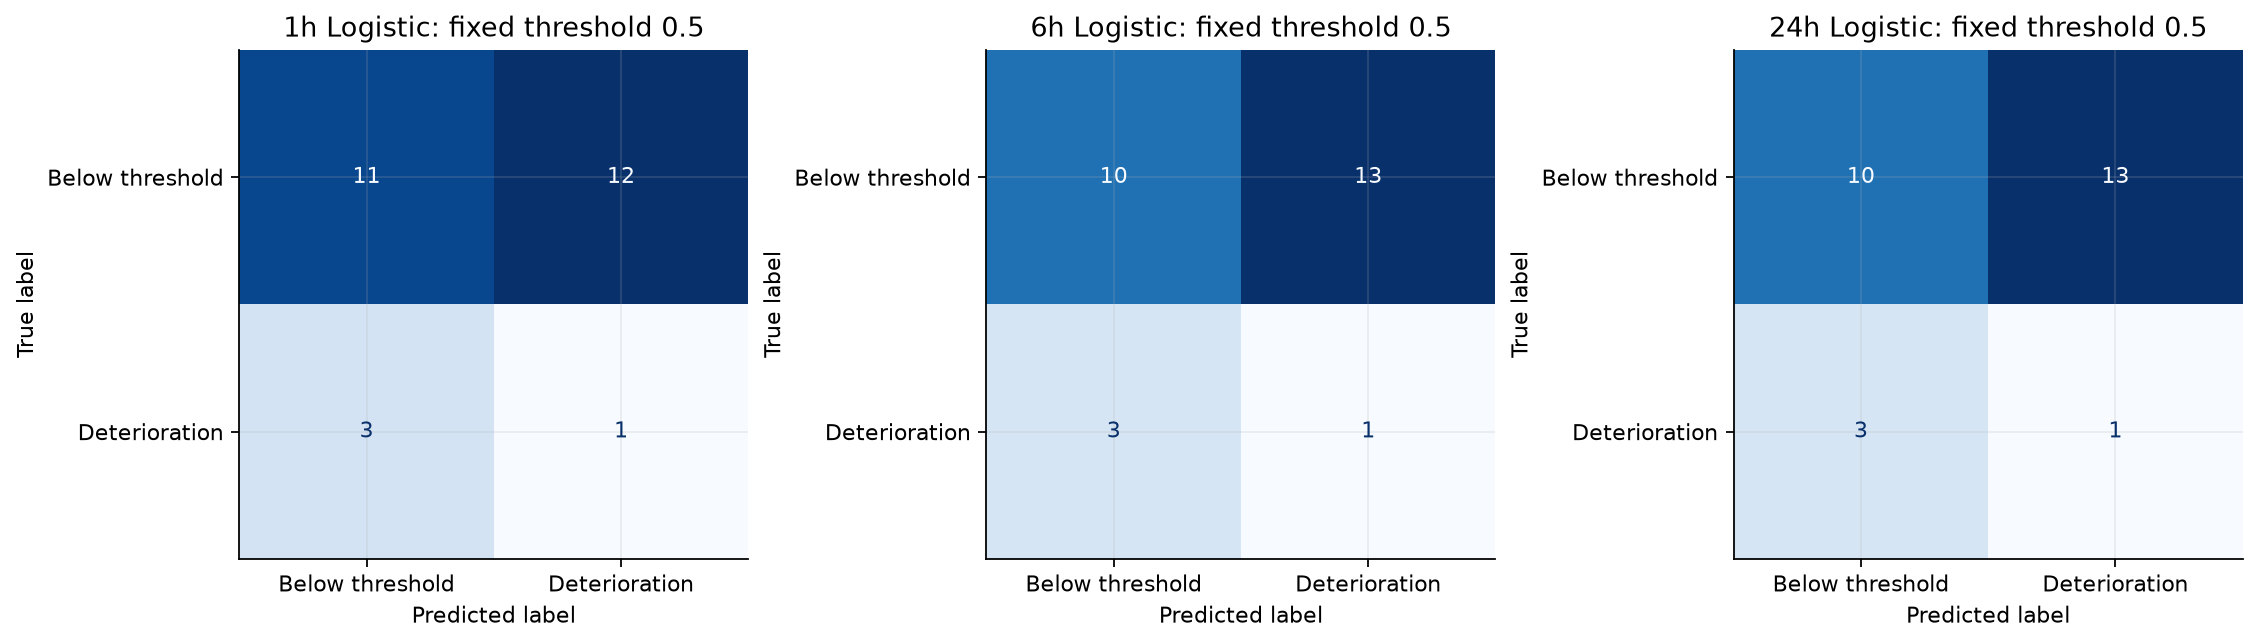

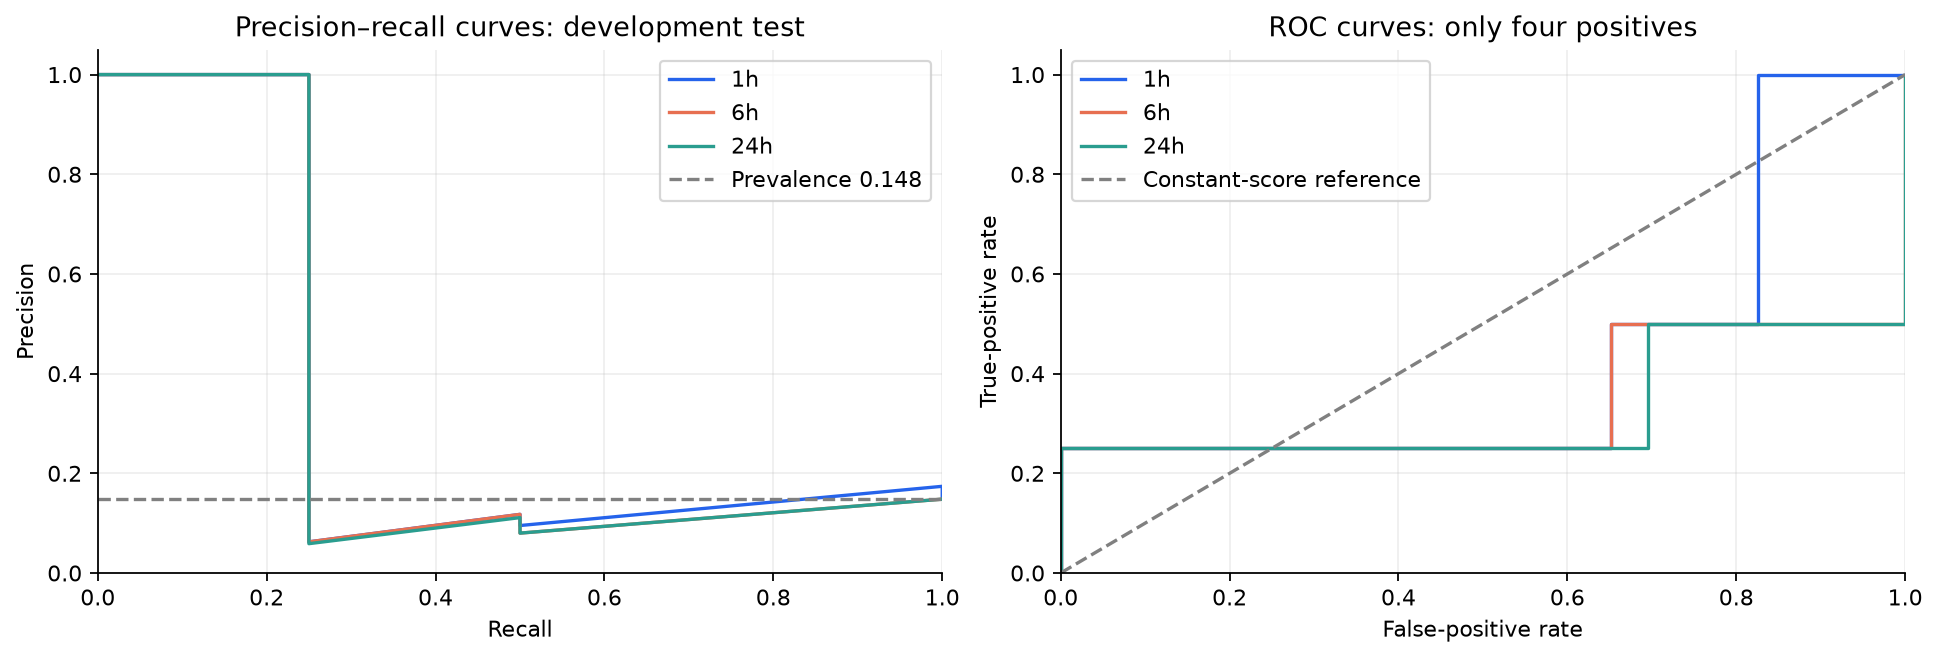

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, window in zip(axes, WINDOWS):
    rows = predictions.query("task == 'classification' and split == 'test' and model == 'logistic_regression' and window_hours == @window")
    matrix = confusion_matrix(rows.observed_provisional_target.astype(int), rows.predicted_class.astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Below threshold", "Deterioration"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{window}h Logistic: fixed threshold 0.5")
show_chart(fig, "12_logistic_confusion_matrices")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for window, color in zip(WINDOWS, COLORS):
    rows = predictions.query("task == 'classification' and split == 'test' and model == 'logistic_regression' and window_hours == @window")
    y = rows.observed_provisional_target.astype(int)
    precision, recall, _ = precision_recall_curve(y, rows.classification_score)
    fpr, tpr, _ = roc_curve(y, rows.classification_score)
    axes[0].plot(recall, precision, label=f"{window}h", color=color)
    axes[1].plot(fpr, tpr, label=f"{window}h", color=color)
prevalence = float(y.mean())
axes[0].axhline(prevalence, linestyle="--", color="gray", label=f"Prevalence {prevalence:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Constant-score reference")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves: development test", xlim=(0, 1), ylim=(0, 1.05))
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curves: only four positives", xlim=(0, 1), ylim=(0, 1.05))
for ax in axes: ax.legend()
show_chart(fig, "13_precision_recall_and_roc")


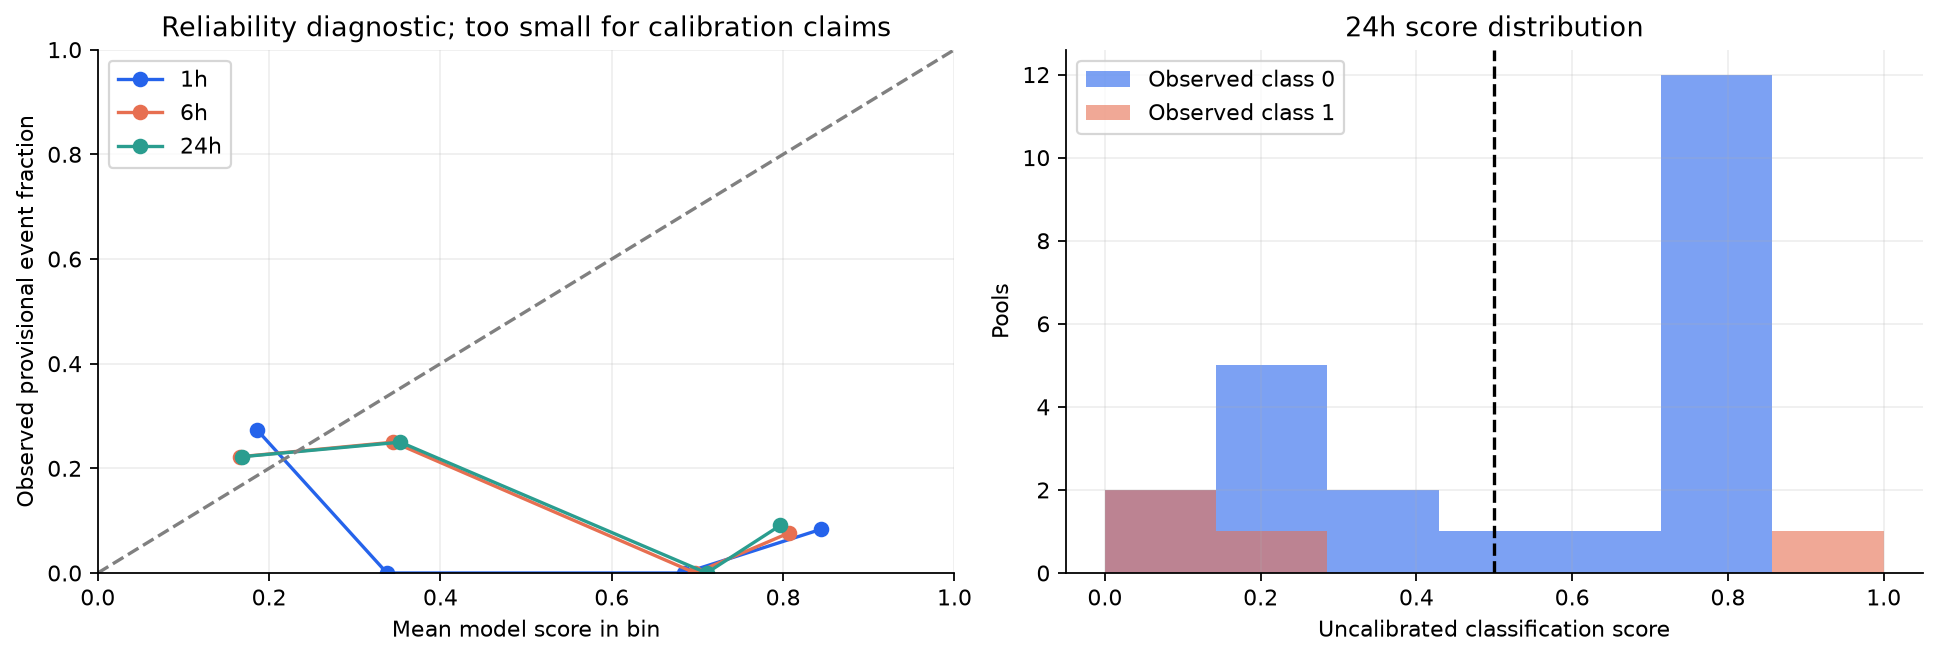

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for window, color in zip(WINDOWS, COLORS):
    rows = predictions.query("task == 'classification' and split == 'test' and model == 'logistic_regression' and window_hours == @window")
    fraction, mean_score = calibration_curve(rows.observed_provisional_target.astype(int), rows.classification_score,
                                             n_bins=4, strategy="uniform")
    axes[0].plot(mean_score, fraction, marker="o", color=color, label=f"{window}h")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(xlabel="Mean model score in bin", ylabel="Observed provisional event fraction",
            title="Reliability diagnostic; too small for calibration claims", xlim=(0, 1), ylim=(0, 1))
axes[0].legend()
rows = predictions.query("task == 'classification' and split == 'test' and model == 'logistic_regression' and window_hours == 24")
for label, color in zip([0, 1], COLORS):
    axes[1].hist(rows.loc[rows.observed_provisional_target == label, "classification_score"],
                 bins=np.linspace(0, 1, 8), alpha=.6, color=color, label=f"Observed class {label}")
axes[1].axvline(.5, color="black", linestyle="--")
axes[1].set(title="24h score distribution", xlabel="Uncalibrated classification score", ylabel="Pools")
axes[1].legend()
show_chart(fig, "14_score_and_reliability_diagnostics")


## 9. Regression evaluation

MAE and RMSE are in **percentage points**, not USD. R² can be negative when a
model performs worse than a constant reference. It is undefined for constant
validation targets. We do not remove the training extreme, clip below-minus-100%
predictions, or switch the target transform after inspecting test scores.


,window_hours,model,n,rmse,mae,r2,predictions_below_minus100
5,1,dummy_mean,27,681.576403,676.027307,-60.664303,0.0
7,1,dummy_median,27,87.332302,38.896770,-0.012406,0.0
9,1,ridge,27,3174.962990,2146.894242,-1337.079963,6.0
15,6,dummy_mean,27,681.576403,676.027307,-60.664303,0.0
17,6,dummy_median,27,87.332302,38.896770,-0.012406,0.0
19,6,ridge,27,3205.389699,2257.141211,-1362.849368,3.0
25,24,dummy_mean,27,681.576403,676.027307,-60.664303,0.0
27,24,dummy_median,27,87.332302,38.896770,-0.012406,0.0
29,24,ridge,27,2414.102066,1972.935151,-772.599158,8.0


,window_hours,model,mae,rmse,r2,metric_warning
4,1,dummy_mean,685.694646,685.694646,NaN,r2_undefined_constant_or_insufficient_targets
6,1,dummy_median,0.000000,0.000000,NaN,r2_undefined_constant_or_insufficient_targets
8,1,ridge,319.397914,319.439758,NaN,r2_undefined_constant_or_insufficient_targets
14,6,dummy_mean,685.694646,685.694646,NaN,r2_undefined_constant_or_insufficient_targets
16,6,dummy_median,0.000000,0.000000,NaN,r2_undefined_constant_or_insufficient_targets
18,6,ridge,374.372572,374.404062,NaN,r2_undefined_constant_or_insufficient_targets
24,24,dummy_mean,685.694646,685.694646,NaN,r2_undefined_constant_or_insufficient_targets
26,24,dummy_median,0.000000,0.000000,NaN,r2_undefined_constant_or_insufficient_targets
28,24,ridge,179.974587,179.991897,NaN,r2_undefined_constant_or_insufficient_targets


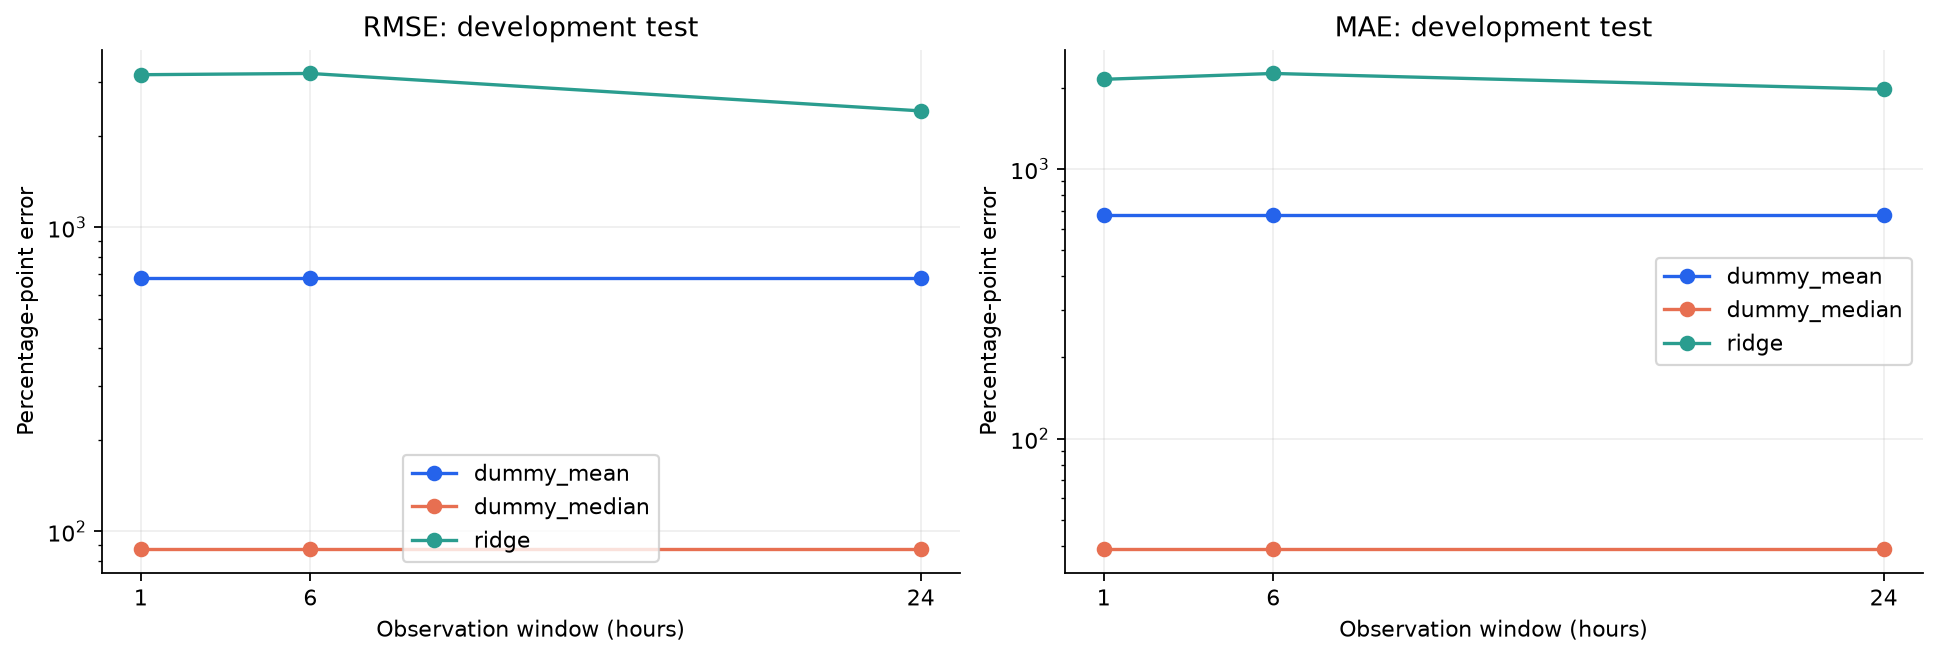

In [18]:
regression = metrics[(metrics.task == "regression") & (metrics.split == "test")]
display(regression[["window_hours", "model", "n", "rmse", "mae", "r2", "predictions_below_minus100"]])
display(metrics[(metrics.task == "regression") & (metrics.split == "validation")][
    ["window_hours", "model", "mae", "rmse", "r2", "metric_warning"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for name, color in zip(["dummy_mean", "dummy_median", "ridge"], COLORS):
    rows = regression[regression.model == name]
    axes[0].plot(rows.window_hours, rows.rmse, marker="o", color=color, label=name)
    axes[1].plot(rows.window_hours, rows.mae, marker="o", color=color, label=name)
for ax, title in zip(axes, ["RMSE", "MAE"]):
    ax.set(title=f"{title}: development test", xlabel="Observation window (hours)",
           ylabel="Percentage-point error", xticks=WINDOWS, yscale="log")
    ax.legend()
show_chart(fig, "15_regression_error_comparison")


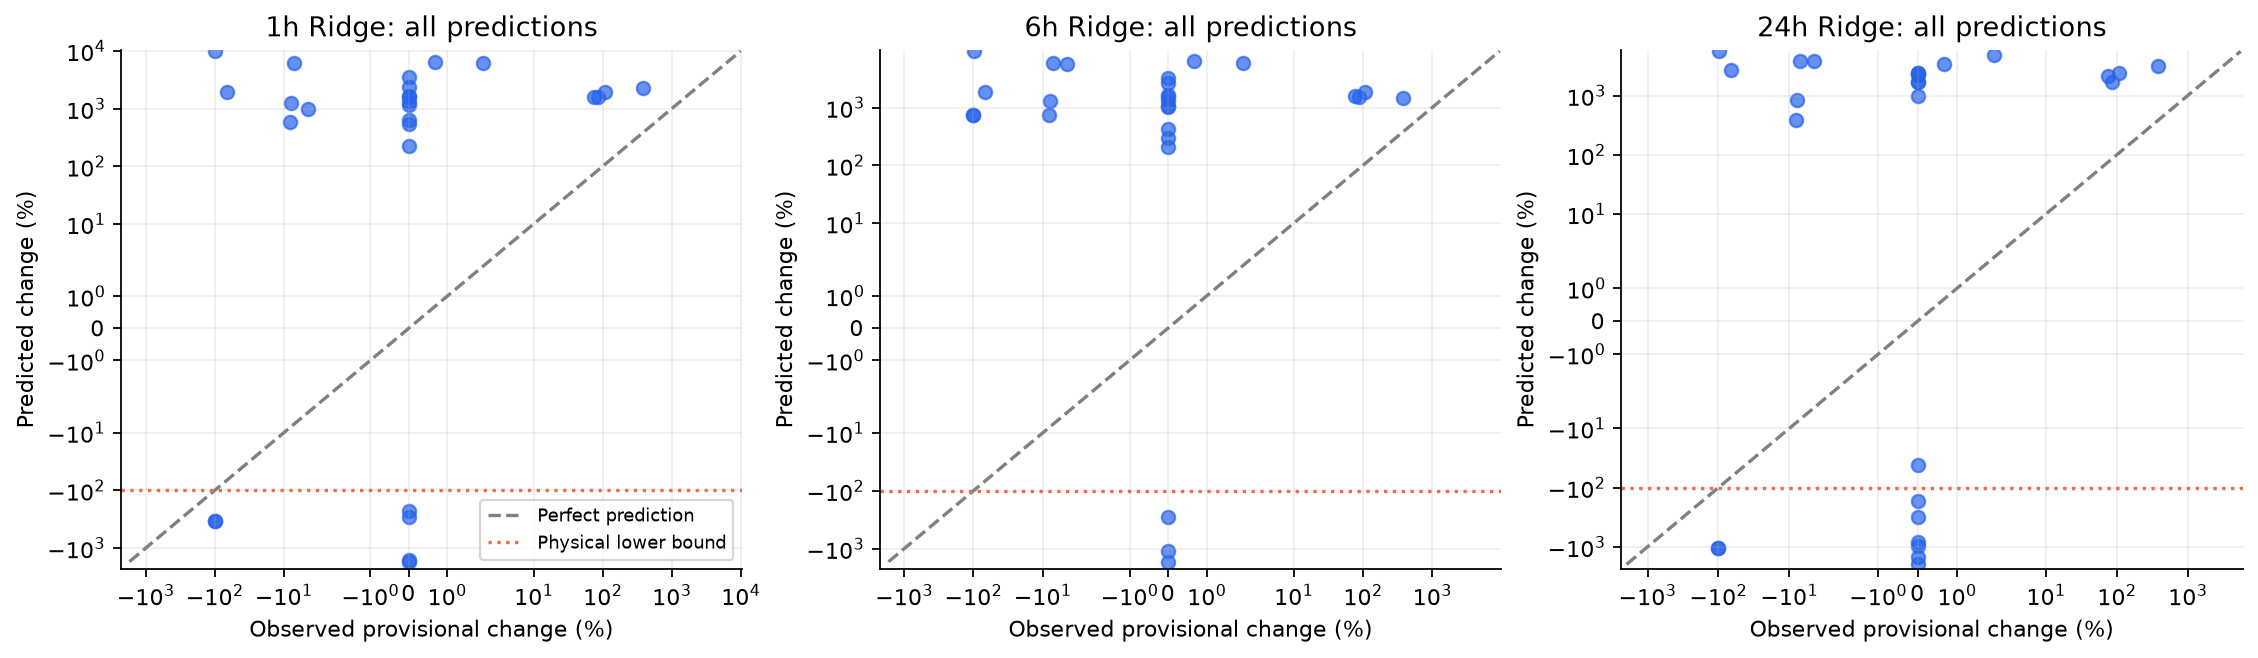

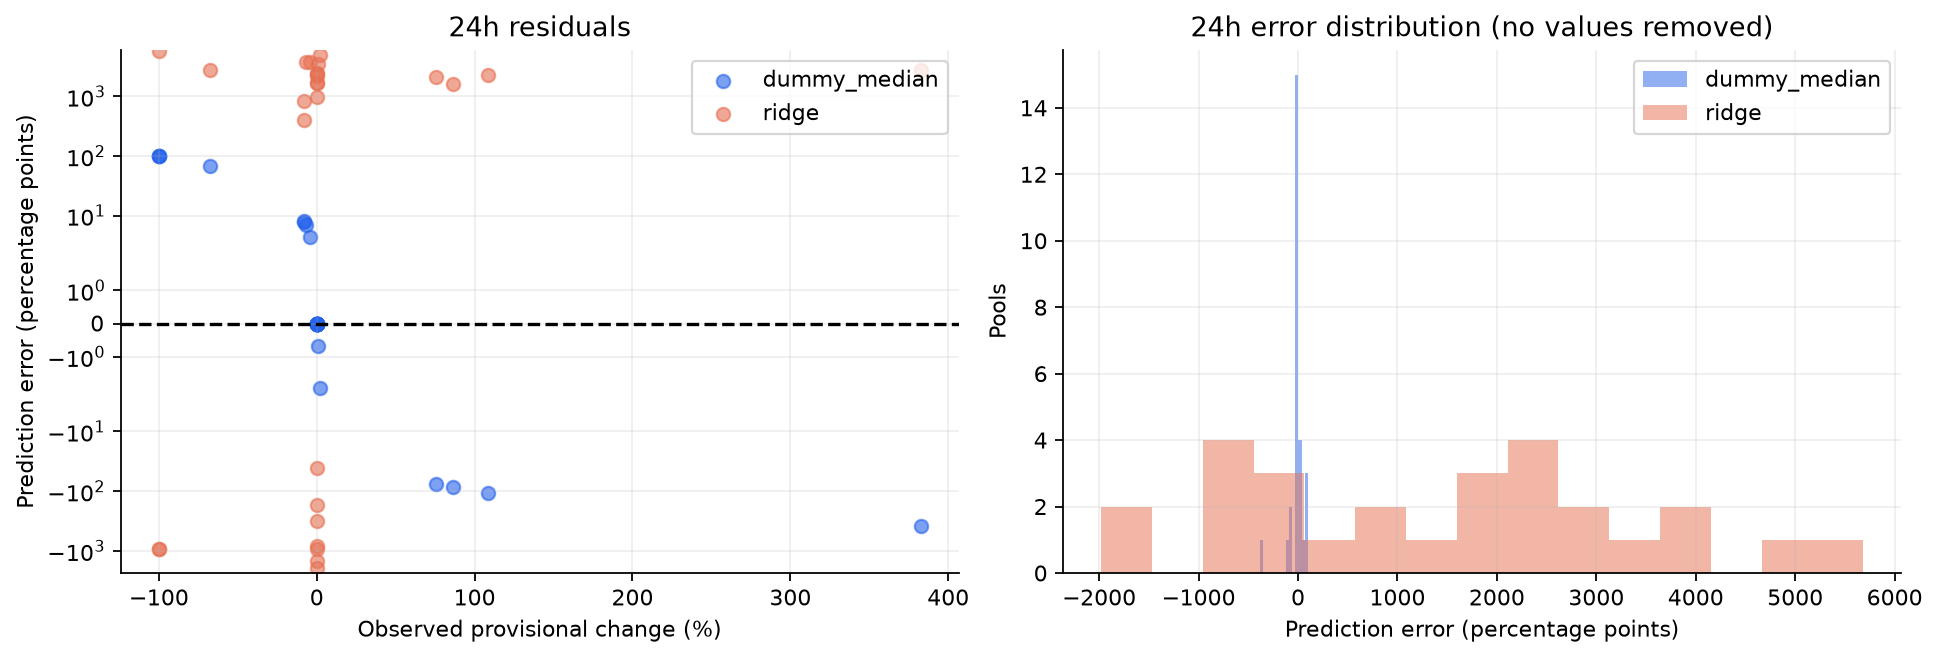

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, window in zip(axes, WINDOWS):
    rows = predictions.query("task == 'regression' and split == 'test' and model == 'ridge' and window_hours == @window")
    x, y = rows.observed_provisional_target, rows.predicted_tvl_change_pct
    ax.scatter(x, y, alpha=.7, color=COLORS[0])
    limits = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(limits, limits, linestyle="--", color="gray", label="Perfect prediction")
    ax.axhline(-100, color=COLORS[1], linestyle=":", label="Physical lower bound")
    ax.set(xscale="symlog", yscale="symlog", title=f"{window}h Ridge: all predictions",
           xlabel="Observed provisional change (%)", ylabel="Predicted change (%)")
axes[0].legend(fontsize=8)
show_chart(fig, "16_observed_vs_predicted_regression")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for name, color in zip(["dummy_median", "ridge"], COLORS):
    rows = predictions.query("task == 'regression' and split == 'test' and model == @name and window_hours == 24")
    residual = rows.predicted_tvl_change_pct - rows.observed_provisional_target
    axes[0].scatter(rows.observed_provisional_target, residual, label=name, color=color, alpha=.6)
    axes[1].hist(residual, bins=15, label=name, color=color, alpha=.5)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title="24h residuals", xlabel="Observed provisional change (%)", ylabel="Prediction error (percentage points)", yscale="symlog")
axes[1].set(title="24h error distribution (no values removed)", xlabel="Prediction error (percentage points)", ylabel="Pools")
for ax in axes: ax.legend()
show_chart(fig, "17_regression_residuals")


## 10. Model interpretation and a historical pool example

The following are **linear coefficients**, not SHAP values and not causal
explanations. Numeric inputs are log-transformed and standardized. Logistic
coefficients affect log-odds; Ridge coefficients affect percentage-change output
for transformed inputs. Fee-tier coefficients refer to one-hot categories.

Random Forest, XGBoost, and SHAP remain later modeling work; no validated winner
can be selected from the current validation group. This notebook covers all
implemented baseline work without fabricating those planned artifacts.


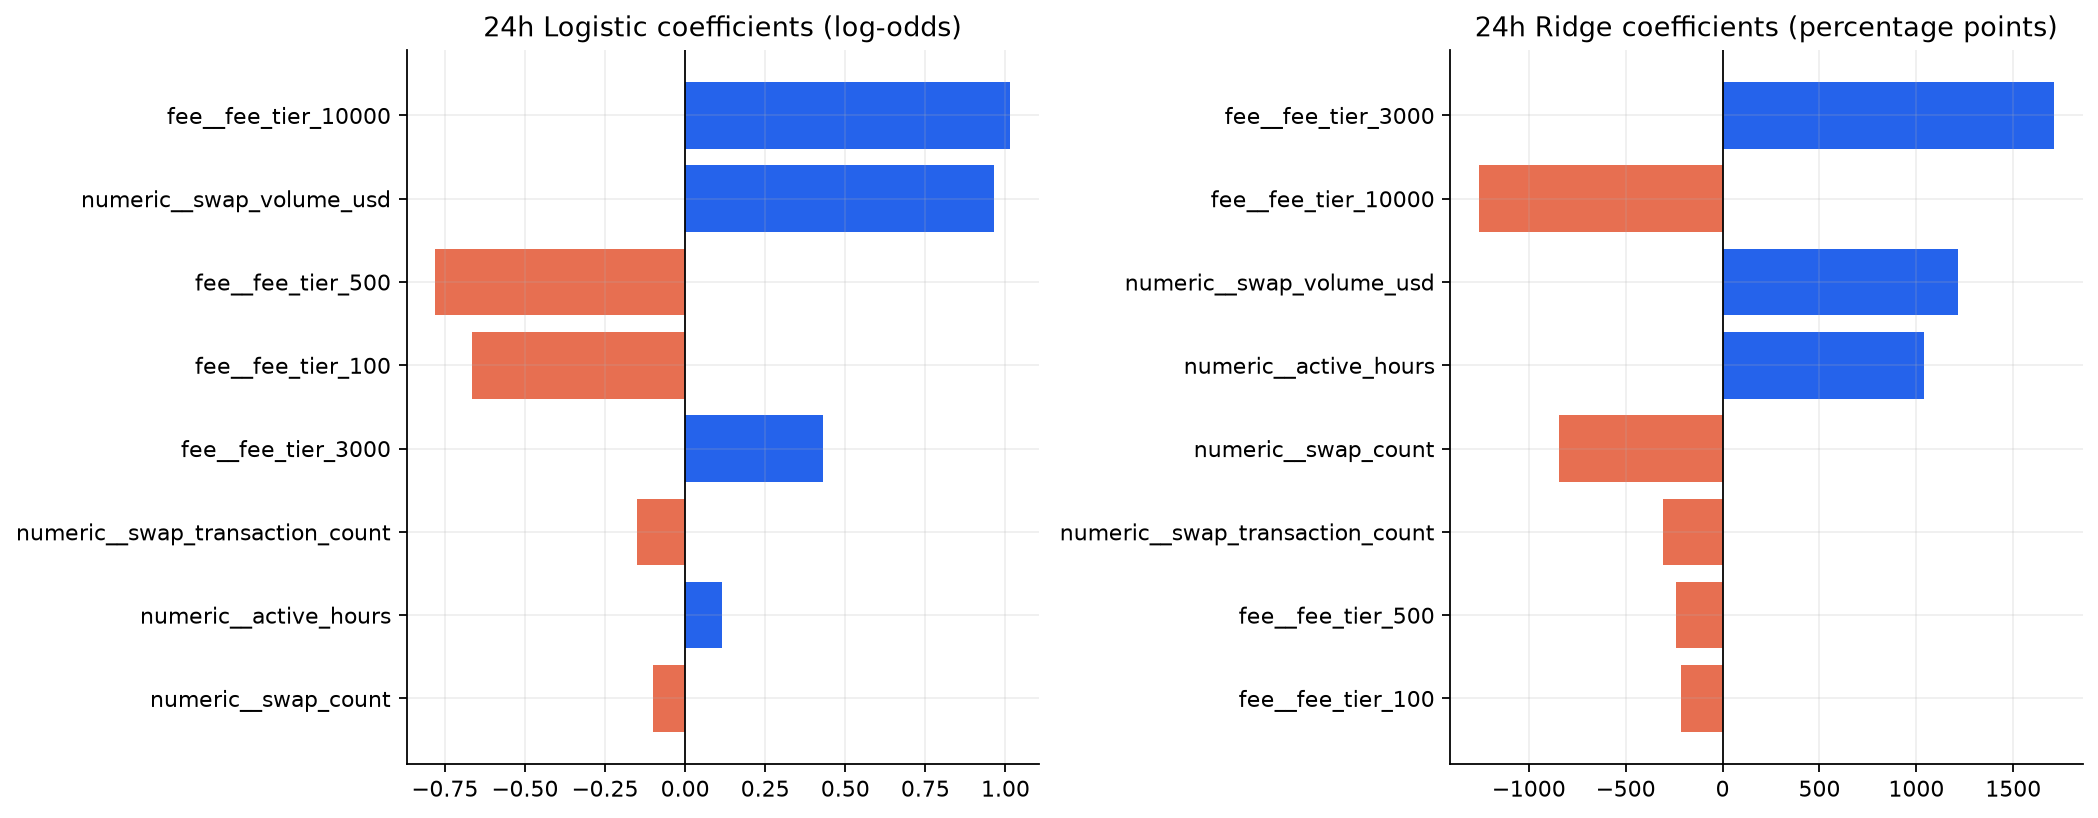

Example development-test pool: 0xe6c627f6a518b8b54d0a9d381b879e1046b539f2


,swap_count,swap_transaction_count,active_hours,swap_volume_usd,fee_tier,feature_eligible
152,29.0,29.0,2.0,26722.719564,3000,True


,window_hours,task,model,classification_score,predicted_class,predicted_tvl_change_pct,observed_provisional_target
12,1,classification,dummy_prior,0.193548,0.0,NaN,0.000000
49,1,classification,logistic_regression,0.877939,1.0,NaN,0.000000
86,1,regression,dummy_mean,NaN,NaN,685.694646,-7.016715
123,1,regression,dummy_median,NaN,NaN,0.000000,-7.016715
160,1,regression,ridge,NaN,NaN,6277.405184,-7.016715
197,6,classification,dummy_prior,0.193548,0.0,NaN,0.000000
234,6,classification,logistic_regression,0.811696,1.0,NaN,0.000000
271,6,regression,dummy_mean,NaN,NaN,685.694646,-7.016715
308,6,regression,dummy_median,NaN,NaN,0.000000,-7.016715
345,6,regression,ridge,NaN,NaN,5833.118039,-7.016715


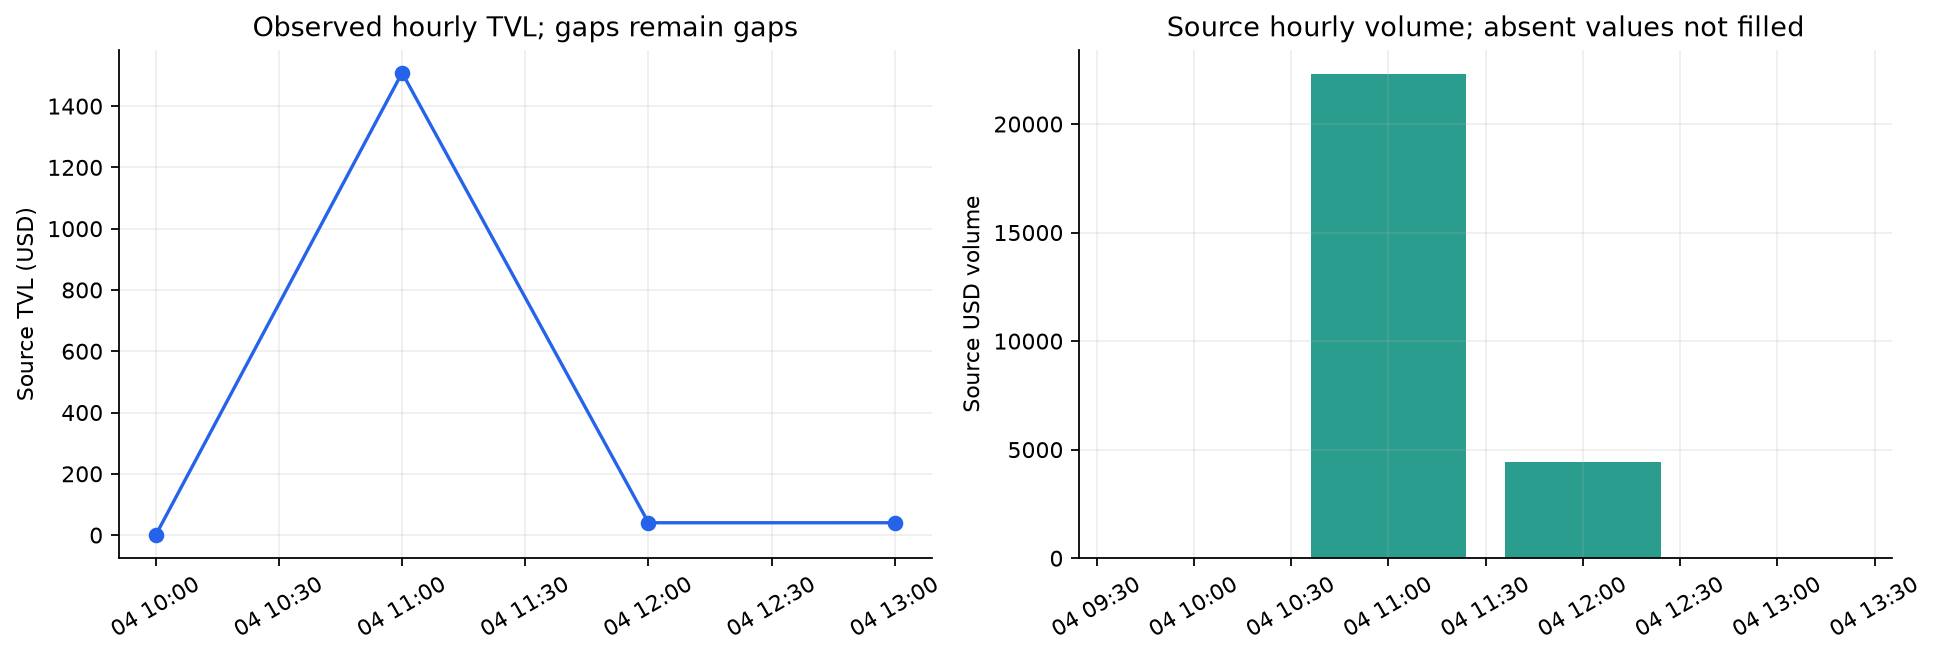

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
coefficient_rows = []
for ax, name, title in zip(axes, ["logistic_regression", "ridge"], ["24h Logistic coefficients (log-odds)", "24h Ridge coefficients (percentage points)"]):
    model = fitted_models[(24, name)]
    names = model.named_steps["preprocess"].get_feature_names_out()
    values = model.named_steps["model"].coef_.reshape(-1)
    order = np.argsort(np.abs(values))
    ax.barh(np.array(names)[order], values[order], color=[COLORS[0] if v >= 0 else COLORS[1] for v in values[order]])
    ax.axvline(0, color="black", linewidth=.8)
    ax.set_title(title)
    for feature, value in zip(names, values):
        coefficient_rows.append({"model": name, "window_hours": 24, "transformed_feature": feature, "coefficient": float(value)})
show_chart(fig, "18_linear_model_coefficients_not_shap")
pd.DataFrame(coefficient_rows).to_csv(OUTPUT / "linear_coefficients.csv", index=False)

# Deterministic selection by creation time; never select an example for a flattering score.
example_id = splits[splits.split == "test"].sort_values("created_at_unix").pool_address
example_id = next(pool for pool in example_id if pool in set(predictions.pool_address))
print("Example development-test pool:", example_id)
display(features_by_window[24].query("pool_address == @example_id")[FEATURES + ["feature_eligible"]])
display(predictions.query("pool_address == @example_id")[["window_hours", "task", "model",
    "classification_score", "predicted_class", "predicted_tvl_change_pct", "observed_provisional_target"]])
example_hours = hourly[hourly.pool_address == example_id].copy()
example_hours["time"] = pd.to_datetime(example_hours.bucket_end_utc, utc=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(example_hours.time, example_hours.tvlUSD, marker="o", color=COLORS[0])
axes[0].set(title="Observed hourly TVL; gaps remain gaps", ylabel="Source TVL (USD)")
axes[1].bar(example_hours.time, example_hours.volumeUSD, width=1/30, color=COLORS[2])
axes[1].set(title="Source hourly volume; absent values not filled", ylabel="Source USD volume")
for ax in axes: ax.tick_params(axis="x", rotation=30)
show_chart(fig, "19_historical_pool_observed_measurements")


## 11. Reproducibility checks and export inventory

Exports are isolated under `data/notebook_outputs/defi_pulse_baseline/`; the
collected dataset and CLI baseline outputs are preserved. Every chart is saved
as PNG and SVG. Model predictions, target/feature versions, source hashes, and
limits travel with the results. The statistics and baseline training are now
readable and executable in this notebook, with reusable core logic in `src/`.


In [21]:
# Reproduce a saved model's predictions and compare this notebook with the CLI run.
sample = predictions.query("window_hours == 24 and model == 'logistic_regression' and split == 'test'")
bundle = joblib.load(OUTPUT / "models/24h_logistic_regression.joblib")
x = features_by_window[24].set_index("pool_address").loc[sample.pool_address, FEATURES]
np.testing.assert_allclose(bundle["pipeline"].predict_proba(x)[:, 1], sample.classification_score, rtol=1e-10, atol=1e-10)
cli_predictions = ROOT / "data/baselines_30pct/experimental/predictions.csv"
if cli_predictions.exists():
    expected = pd.read_csv(cli_predictions)
    keys = ["pool_address", "window_hours", "task", "model", "split"]
    actual_sorted = predictions.sort_values(keys).reset_index(drop=True)
    expected_sorted = expected.sort_values(keys).reset_index(drop=True)
    assert actual_sorted[keys].equals(expected_sorted[keys])
    for column in ["classification_score", "predicted_tvl_change_pct", "observed_provisional_target"]:
        np.testing.assert_allclose(actual_sorted[column].astype(float), expected_sorted[column].astype(float), equal_nan=True,
                                   rtol=1e-10, atol=1e-10)
    print("Notebook predictions reproduce the existing CLI baseline results.")
for name, expected_hash in input_hashes.items():
    assert file_hash(SOURCE / name) == expected_hash, "Source data changed during notebook execution."
assert CONFIG == frozen_config
manifest = {"purpose": "Executed baseline notebook; experimental provisional targets",
    "created_at_utc": datetime.now(timezone.utc).isoformat(), "versions": versions,
    "input_sha256": input_hashes, "configuration": frozen_config, "network_attempts": 0,
    "model_count": len(fitted_models), "prediction_rows": len(predictions), "metric_records": len(metrics),
    "charts": chart_files, "mann_whitney_rows": len(mann_whitney), "chi_square_rows": len(chi_square),
    "limitations": ["Unverified USD valuations and no final labels", "Previously explored development cohort",
                    "Single-class/constant validation targets", "Small positive count and extreme regression targets",
                    "Coefficients are not SHAP; no validated best model or calibrated risk"]}
manifest["artifact_sha256"] = {str(p.relative_to(OUTPUT)): file_hash(p)
    for p in OUTPUT.rglob("*") if p.is_file() and p.name not in ["manifest.json", "notebook.html"]}
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
display(pd.DataFrame({"artifact": ["targets", "splits", "features_1h/6h/24h", "predictions", "metrics",
                                            "mann_whitney_training", "chi_square_training", "charts/", "models/", "manifest.json"],
                      "purpose": ["Versioned provisional outcomes and quality", "Shared chronological assignments",
                                  "Raw model inputs", "Pool-level class/regression outputs", "Evaluation and undefined-metric flags",
                                  "Training-only continuous comparisons", "Training-only categorical comparison and assumptions",
                                  "Standalone PNG/SVG figures", "Saved pipelines and metadata", "Versions, hashes, and caveats"]}))
print("Charts saved:", len(chart_files), "| Models:", len(fitted_models), "| Predictions:", len(predictions))
print("Output directory:", OUTPUT)


Notebook predictions reproduce the existing CLI baseline results.


,artifact,purpose
0,targets,Versioned provisional outcomes and quality
1,splits,Shared chronological assignments
2,features_1h/6h/24h,Raw model inputs
3,predictions,Pool-level class/regression outputs
4,metrics,Evaluation and undefined-metric flags
5,mann_whitney_training,Training-only continuous comparisons
6,chi_square_training,Training-only categorical comparison and assum...
7,charts/,Standalone PNG/SVG figures
8,models/,Saved pipelines and metadata
9,manifest.json,"Versions, hashes, and caveats"


Charts saved: 19 | Models: 15 | Predictions: 555
Output directory: /mnt/d/mubeen/defi-pulse/data/notebook_outputs/defi_pulse_baseline


## 12. Conclusions and next steps

- The cached source supports factual activity counts for all 200 pools, without
  inventing trades or imputing TVL/price. Rich hourly trajectories remain sparse.
- The 30% rule yields 25 positive and 157 negative **candidates**; 18 cases remain
  excluded by structural checks. USD pricing is not independently verified.
- The embargo and quality gates leave 93 training, 10 validation, and 27 test
  pools. Validation contains no positive cases and no regression variation.
- Logistic Regression detects one of four test positives with many false alarms;
  Ridge loses substantially to the median dummy in the current raw-target run.
  These results do not establish useful prediction, calibration, or causality.
- More elapsed time did not make most sampled pools active. Quiet pools must not
  be discarded merely to make the dataset look complete or improve scores.
- Next: audit source valuation/tiny denominators, establish supported feature and
  target policies, then acquire appropriately spaced new cohorts for genuine
  validation and untouched evaluation. Do not tune against these charts.

References: [project methodology](../docs/methodology.md),
[baseline report](../docs/baselines.md), [modeling specification](../docs/modeling_update.md),
[SciPy Mann–Whitney U](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html),
[SciPy chi-square](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).
